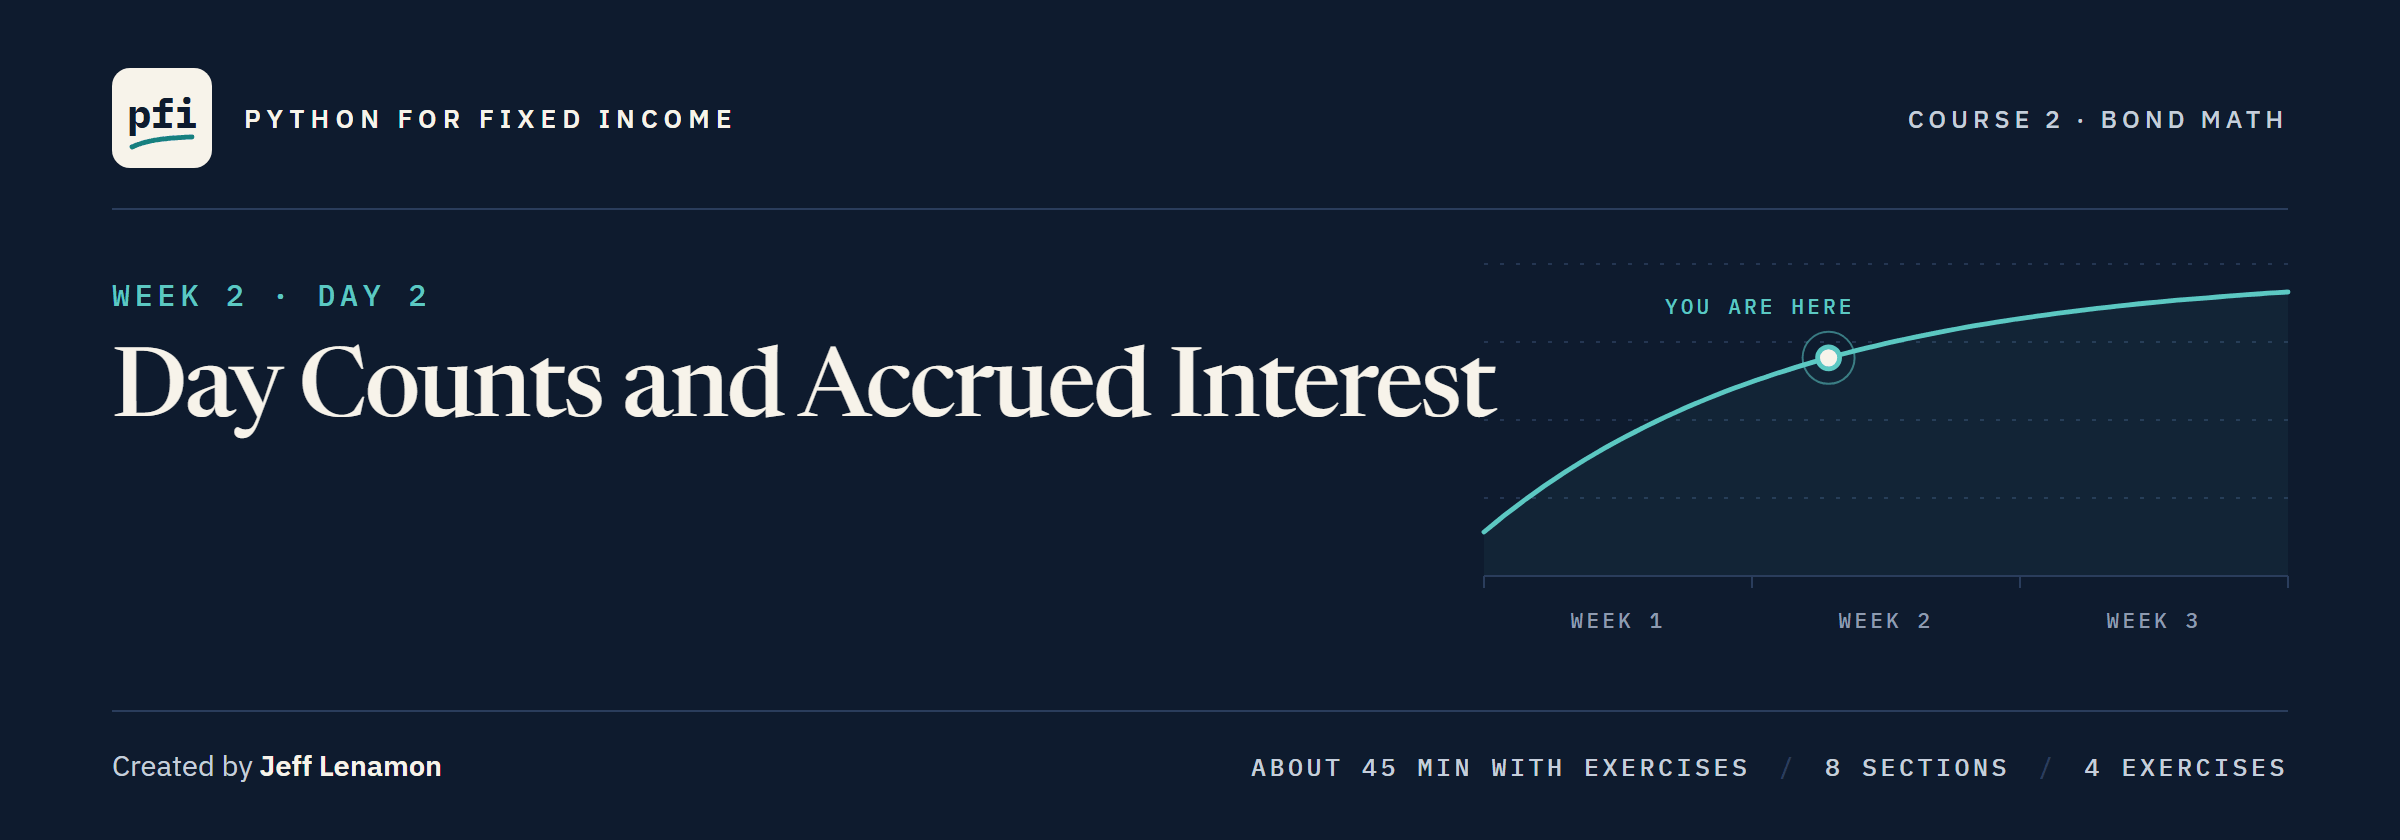

# Day Counts and Accrued Interest

Week 2, Day 2. What a buyer owes the seller between coupons: 30/360 and actual/actual, the day counts A, E, and DSC, and three functions tied to Excel and to the holdings file.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week2/day2/07_day_counts_and_accrued_interest.ipynb)

### The Desk Lead's Note

> We buy 1,000,000 of Quorvane Energy, settling Monday 30 November, two months into its coupon period. The seller wants paying for the interest it earned: how much per 100 and in dollars, and why does a calendar give another number? Put the day counts and accrued interest in `bondmath`, tested against Excel. An assistant has offered to tidy that code; read its change before you take it. Last, show me the holdings file's `accrued` column is right for all 200 bonds.

**Notebook 06 found the dates; today counts the days between them.**

### Today's Work Folder, and Its Tests

Q. Set up the day: how many tests pass this morning?

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module, its tests, and its Git history
# as notebook 06 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(7)

Work folder pfi_course2_07_k4w7q2xr: 3 data files, the module as notebook 06 left it, 6 commits, tagged week1


In [2]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...............                                                          [100%]
15 passed in 0.50s



**The module starts the day as notebook 06 left it: eight functions, 15 tests.**

### Imports

In [3]:
import importlib
from datetime import date, timedelta

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])
# the module the setup copied into the work folder
import bondmath

### The Four Bonds

The issuers are invented; every statement describes the data.

In [4]:
# week 1's four bonds, the maturities typed as dates
bonds = pd.DataFrame({
    'cusip': ['99001BZA7', '99002CZA4', '99003DZA1', '99004EZA8'],
    'ticker': ['QVNE', 'DNMR', 'PLWK', 'HLVF'],
    'coupon_pct': [5.25, 6.125, 4.75, 7.5],
    'maturity': [date(2031, 9, 30), date(2033, 9, 30), date(2029, 9, 30), date(2036, 9, 30)],
})
settlement = date(2026, 11, 30)
quorvane_maturity = date(2031, 9, 30)
bonds

,cusip,ticker,coupon_pct,maturity
0,99001BZA7,QVNE,5.250,2031-09-30
1,99002CZA4,DNMR,6.125,2033-09-30
2,99003DZA1,PLWK,4.750,2029-09-30
3,99004EZA8,HLVF,7.500,2036-09-30


All four accrue from 30 September 2026 and next pay on 31 March 2027, as notebook 06's `coupon_dates` found.

## Your Route Through Day 2

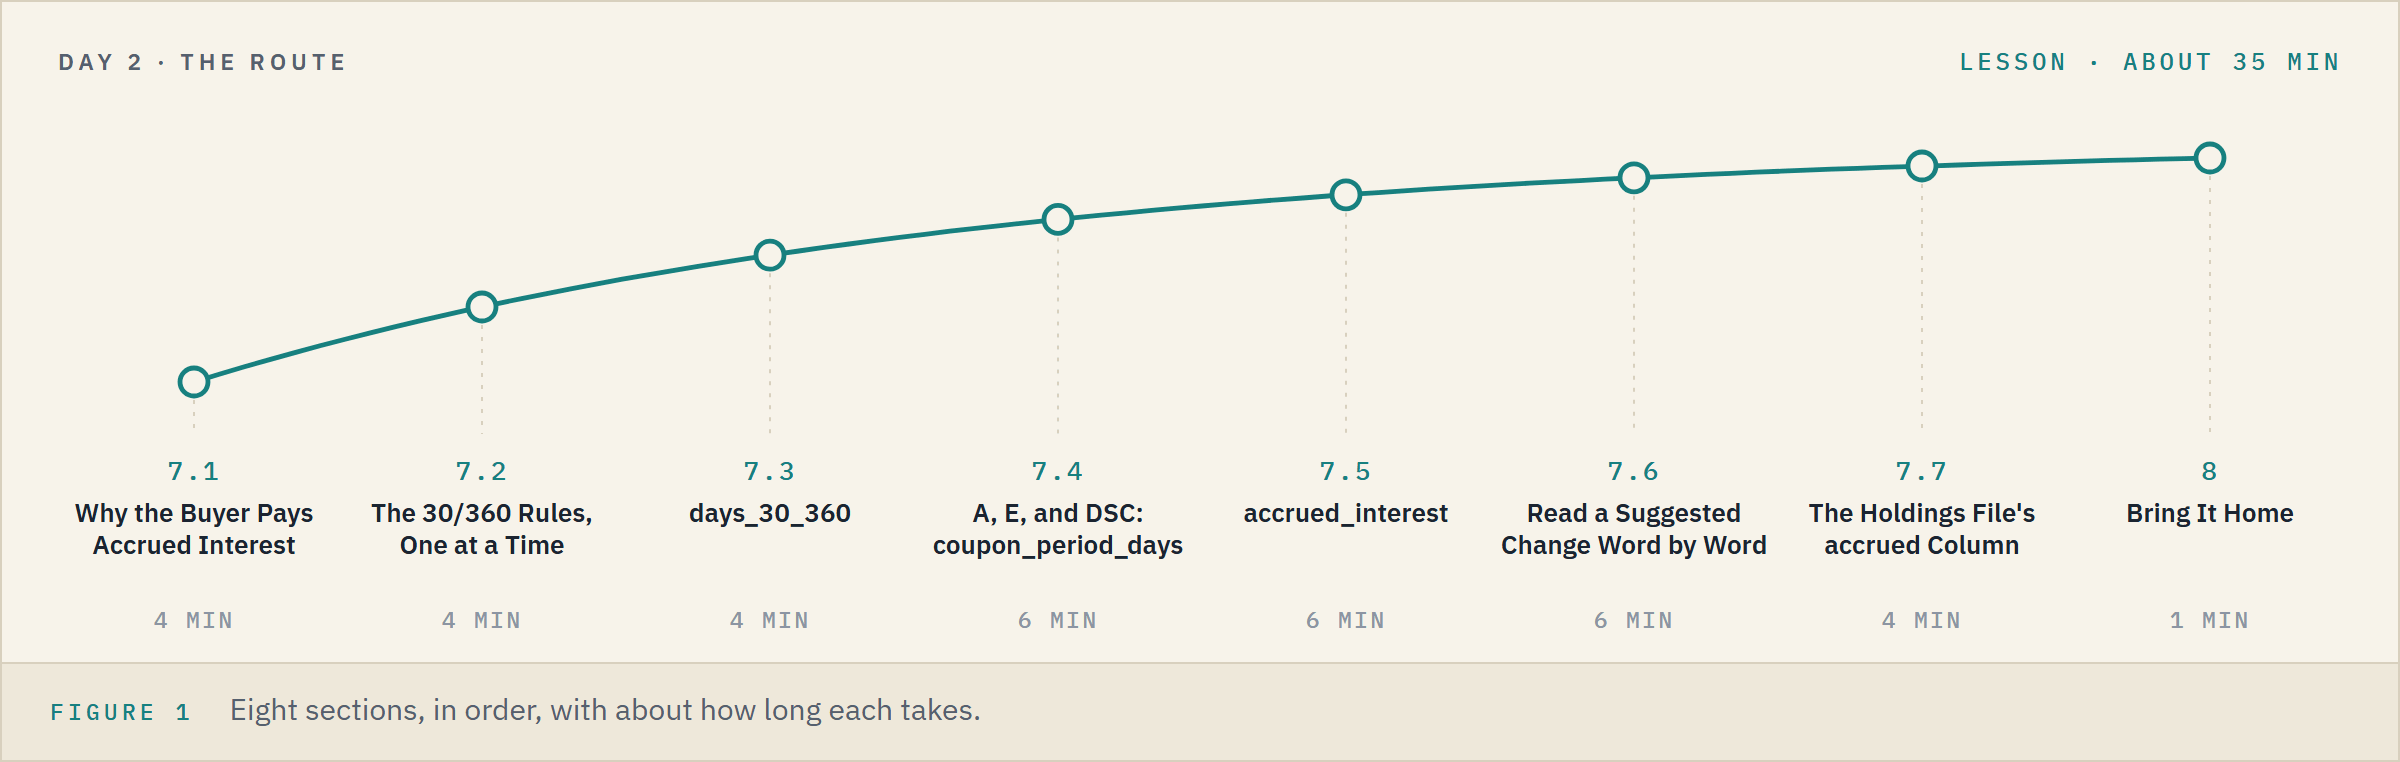

**Time.** About 35 minutes for the lesson, then about 12 for the four exercises.

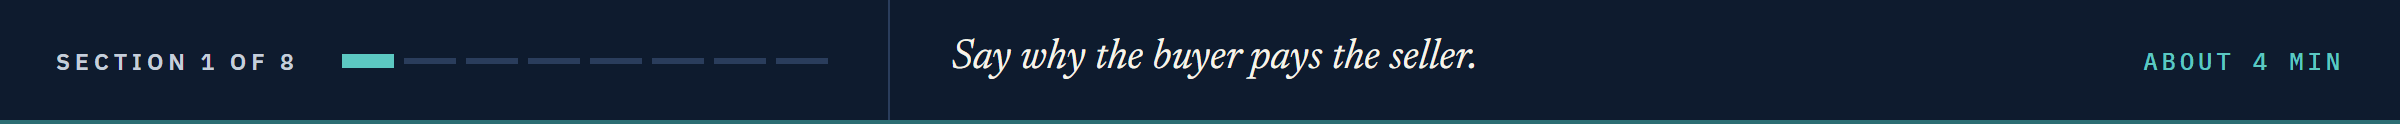

## 7.1 Why the Buyer Pays Accrued Interest

Quorvane pays its whole coupon, 5.25 / 2 = 2.625 per 100, on 31 March to the holder on record.
The seller held it from 30 September to 30 November and earned part of that coupon.
So at settlement the buyer pays the seller that part, the **accrued interest**, on top of the quoted price:

accrued = coupon_pct / frequency x A / E

A is the days accrued, from the previous coupon to settlement, and E the days in the coupon period.
A **day count convention** is the bond's rule for counting them.

### Count Calendar Days

Q. What share of the coupon has the seller earned, counting calendar days?

In [5]:
previous_coupon = date(2026, 9, 30)
next_coupon = date(2027, 3, 31)
# A and E as calendar days
days_held = (settlement - previous_coupon).days
days_in_period = (next_coupon - previous_coupon).days
accrued_actual = 5.25 / 2 * days_held / days_in_period
print(f'{days_held} of {days_in_period} days: accrued {accrued_actual:.6f} per 100')

61 of 182 days: accrued 0.879808 per 100


### Predict 1: Count It 30/360

**Predict 1**

30/360 counts every month as 30 days: two months are 60 days, and a half-year 180.

Q. Against the calendar's 0.879808, the accrued on 30/360 is:

A) the same
B) a little higher
C) a little lower

In [6]:
accrued_30 = 5.25 / 2 * 60 / 180
print(f'30/360: accrued {accrued_30:.6f} per 100')

30/360: accrued 0.875000 per 100


### Excel's Answer

In [7]:
# Excel's answers, one row per case; the week2 rows are the bonds settled on 30 November
reference = pd.read_csv('bondmath_excel_reference.csv', index_col='case_id')
week2 = reference[reference['group'] == 'week2']
excel_accrued = week2.loc['99001BZA7', 'accrued']
print(f'Excel: {excel_accrued:.6f} per 100')
print(f'On 1,000,000 of face: {excel_accrued / 100 * 1_000_000:,.2f} dollars')

Excel: 0.875000 per 100
On 1,000,000 of face: 8,750.00 dollars


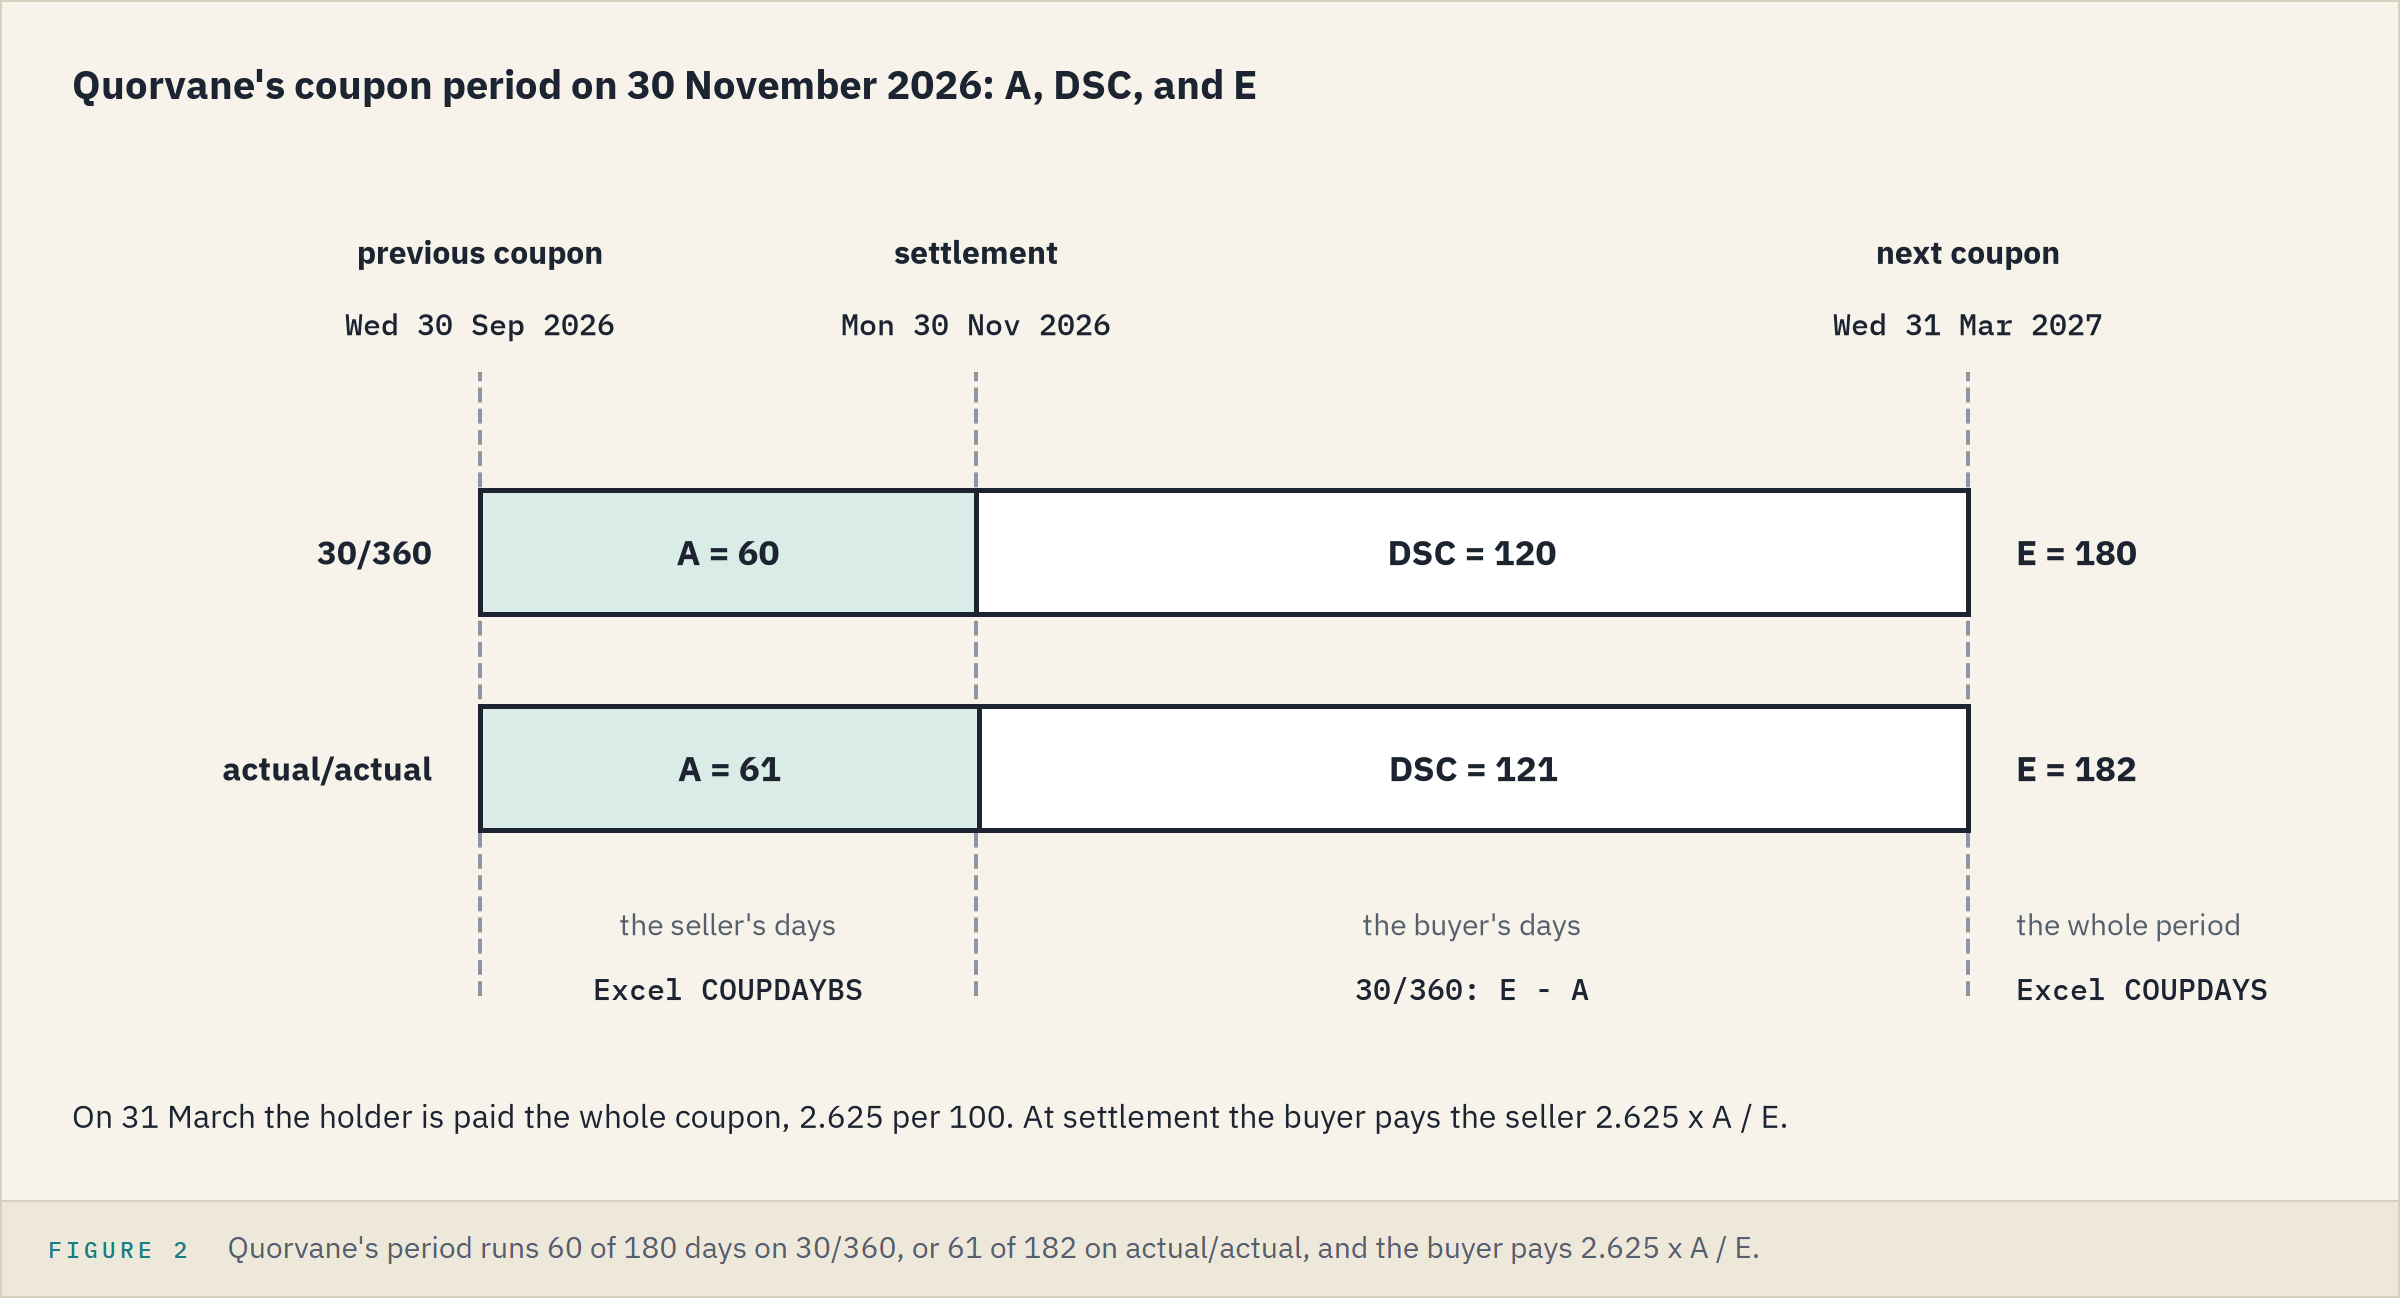

C.
Quorvane's documents name 30/360, so the desk pays 0.875: the calendar's count is another convention, not a mistake.
DSC is the buyer's days, from settlement to the next coupon.

**Excel side by side.**
`COUPDAYBS` is Excel's A and `COUPDAYS` its E; `YEARFRAC(start, end, 0)` is the year fraction on 30/360.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Calendar days</td><td align="left"><code>(settlement - previous_coupon).days</code></td><td align="left"><code>=DATE(2026,11,30)-DATE(2026,9,30)</code></td><td align="left">61</td></tr>
<tr><td align="left">30/360 days</td><td align="left">two months of 30 days</td><td align="left"><code>=YEARFRAC(DATE(2026,9,30),DATE(2026,11,30),0)*360</code></td><td align="left">60</td></tr>
<tr><td align="left">Accrued per 100</td><td align="left"><code>5.25 / 2 * 60 / 180</code></td><td align="left"><code>=100*5.25/100/2*COUPDAYBS(DATE(2026,11,30),DATE(2031,9,30),2,0)/COUPDAYS(DATE(2026,11,30),DATE(2031,9,30),2,0)</code></td><td align="left">0.875</td></tr>
</table>
<br clear="left">

`100*` makes it per 100 of face, and `5.25/100` turns the percent into Excel's decimal.

**"How many days" is the bond's convention, not the calendar's: Quorvane is 30/360, and Excel says 0.875.**

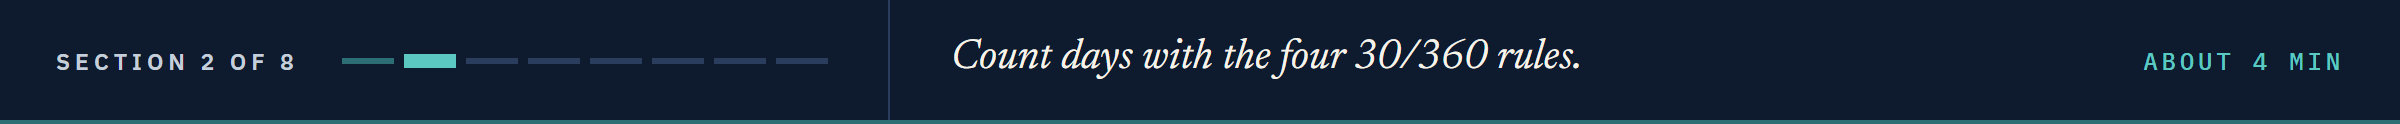

## 7.2 The 30/360 Rules, One at a Time

30/360 counts with one formula, Y, M, and D being the year, month, and day of the start (1) and the end (2):

Days = 360 x (Y2 - Y1) + 30 x (M2 - M1) + (D2 - D1)

### The Formula, No Rules

Q. Count 16 August to 30 September 2026, then 31 August to 30 September.

In [8]:
end = date(2026, 9, 30)
for start in [date(2026, 8, 16), date(2026, 8, 31)]:
    # the formula on each date's day numbers, unchanged
    days = 360 * (end.year - start.year) + 30 * (end.month - start.month) + (end.day - start.day)
    print(f'{start} to {end}: {days} days')

2026-08-16 to 2026-09-30: 44 days
2026-08-31 to 2026-09-30: 29 days


44 is right, 30 x 1 + (30 - 16), but 31 August to 30 September is one whole month, and the formula says 29.
So US 30/360 first moves D1 or D2 at month ends, by four rules, in order.

### Predict 2: 28 February to 31 March

**Predict 2**

28 February 2027 is the last day of February, and 31 March is a 31st: a month end at each side.

Q. What does Excel count from 28 February to 31 March 2027 on 30/360?

A) 30, one whole month, as 31 August to 30 September should be
B) 31, one month and a day
C) 33, the formula with no rule

### Excel Decides

In [9]:
# the reference row whose previous coupon and settlement are these two dates
row = reference.loc['edge_settle_31_mar_after_feb_end']
print('previous coupon', row['couppcd'], ' settlement', row['settlement'],
      ' COUPDAYBS', row['coupdaybs'])

previous coupon 2027-02-28  settlement 2027-03-31  COUPDAYBS 31


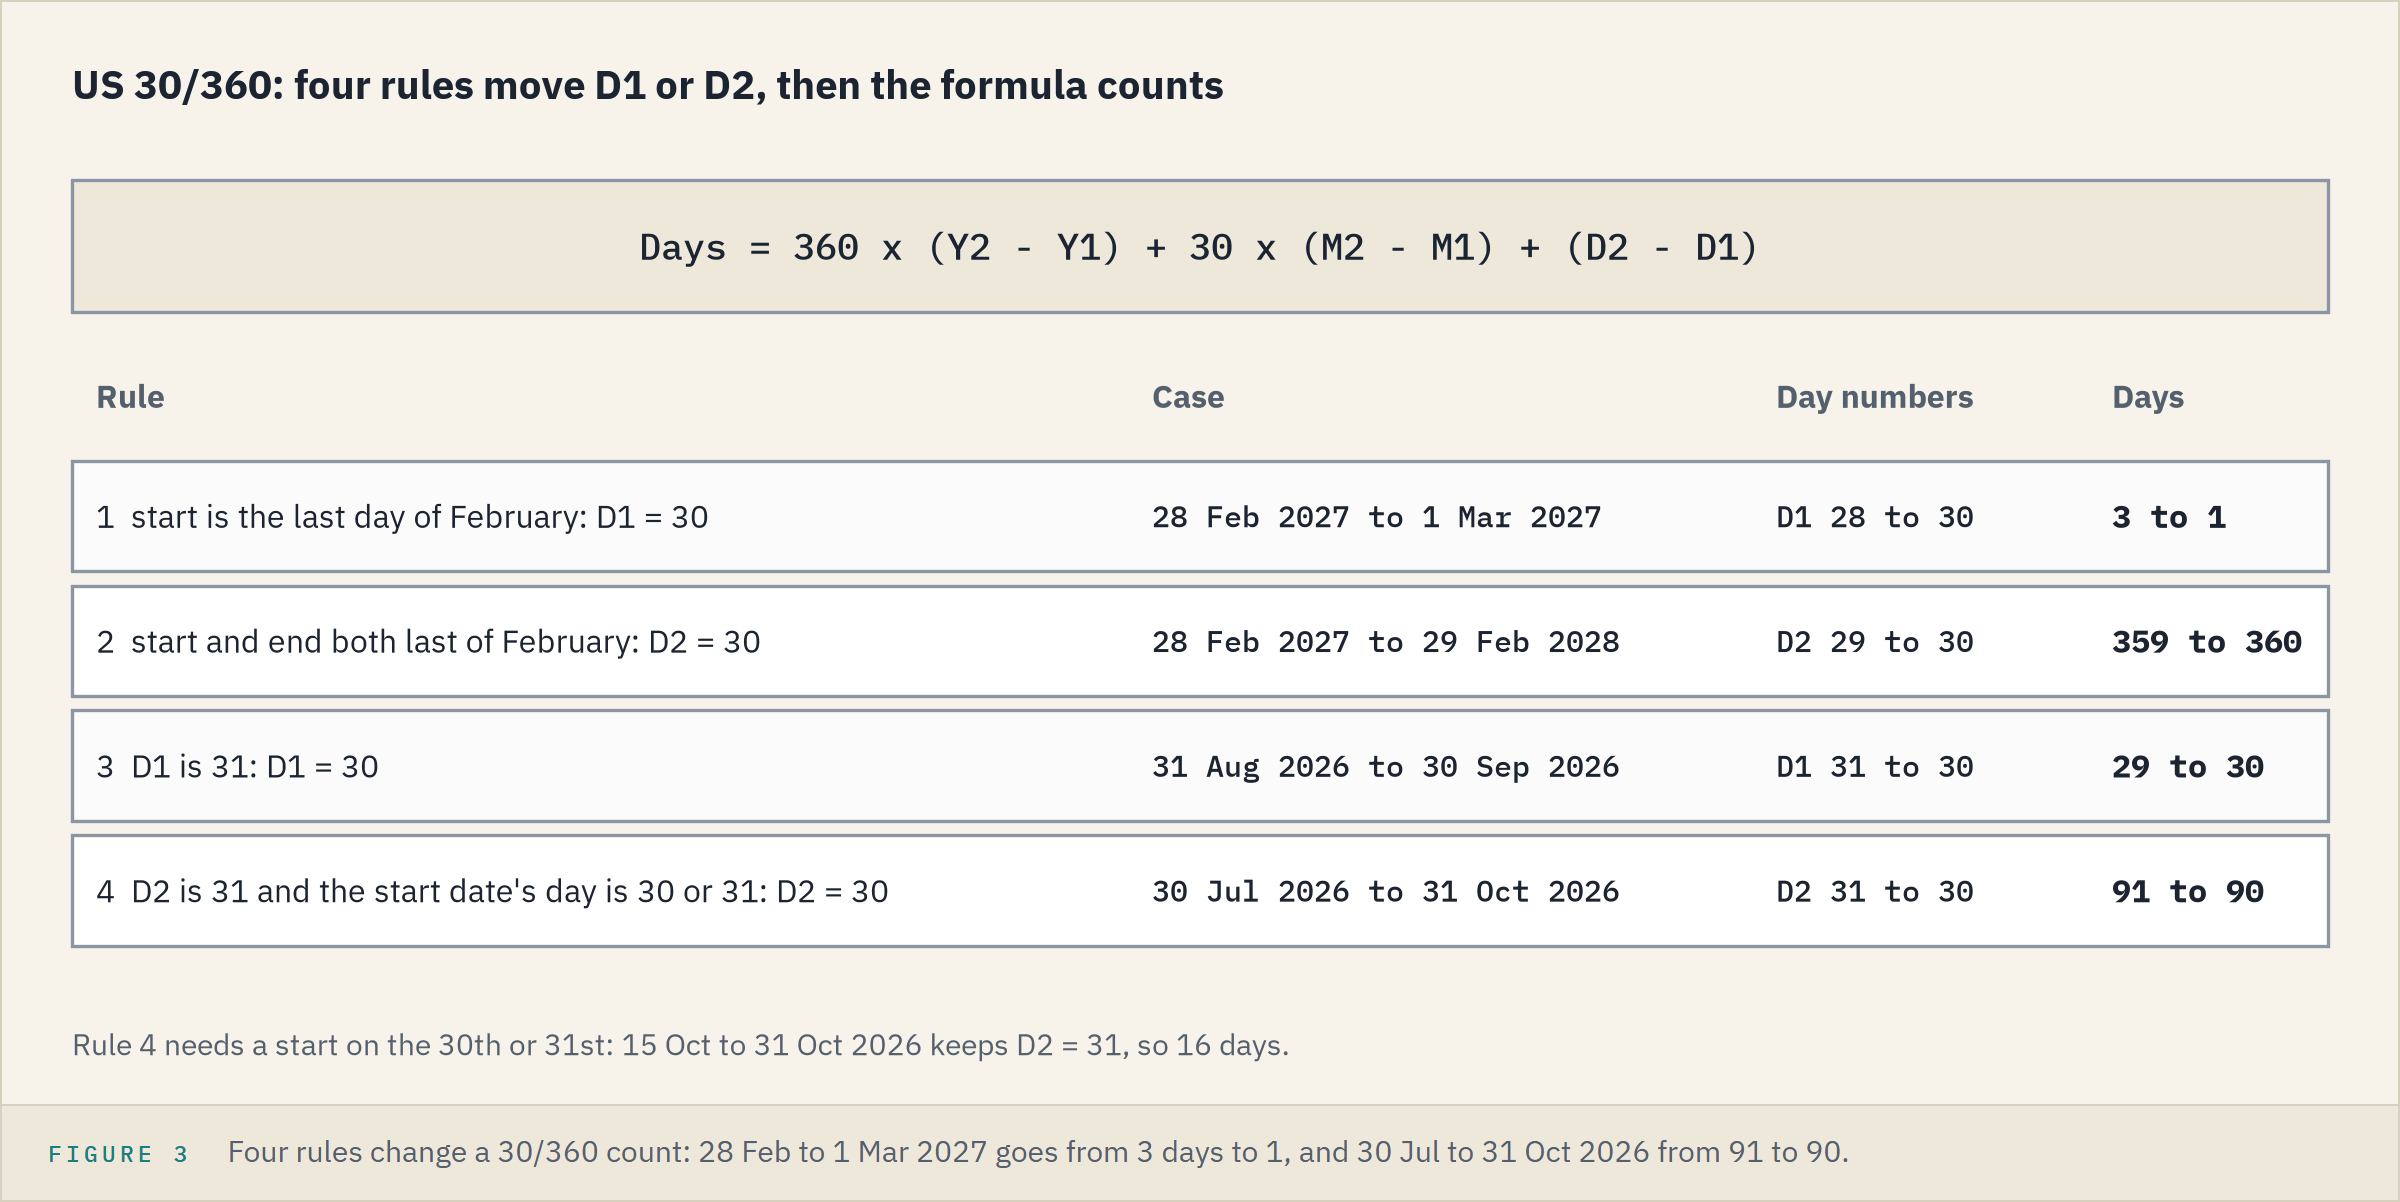

B.
Rule 1 makes D1 30, since the 28th is the last day of February.
Rule 4 reads the start date as it is on the calendar, the 28th, so D2 keeps 31: 30 x 1 + (31 - 30) = 31.
In a sheet, `=COUPDAYBS(DATE(2027,3,31),DATE(2031,8,31),2,0)` returns 31.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">The formula, start in A1 and end in B1</td><td align="left"><code>days</code>, above</td><td align="left"><code>=360*(YEAR(B1)-YEAR(A1))+30*(MONTH(B1)-MONTH(A1))+(DAY(B1)-DAY(A1))</code></td><td align="left">44, then 29</td></tr>
<tr><td align="left">Rule 3 in the sheet</td><td align="left">D1 = 30 when it is 31</td><td align="left">the same, with <code>MIN(DAY(A1),30)</code> for <code>DAY(A1)</code></td><td align="left">30</td></tr>
</table>
<br clear="left">

**Every rule is about a month end; where a rule can be read two ways, the course counts as Excel does.**

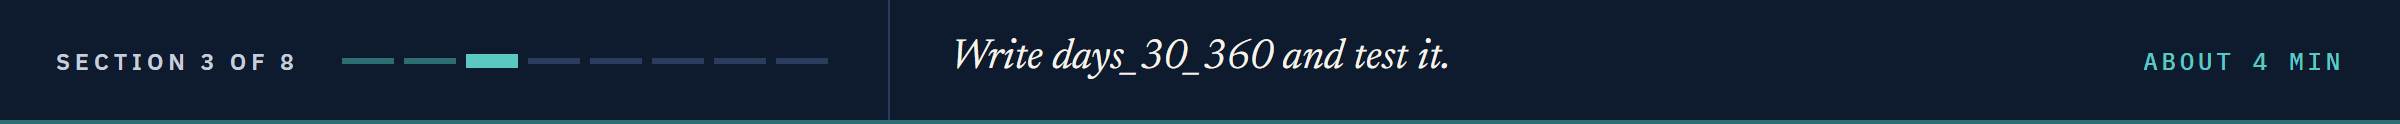

## 7.3 `days_30_360`

### Append It, Docstring First

`days_30_360(start, end)` first asks whether each date is the last day of February (`calendar.monthrange`, as in notebook 06), then applies the four rules in order, then the formula.
Its docstring gives the units, the rules, and the Excel functions that count the same way.

Q. Append `days_30_360` to `bondmath.py`.

In [10]:
%%writefile -a bondmath.py


def days_30_360(start: date, end: date) -> int:
    """Days from start to end on the US 30/360 basis, as Excel's COUPDAYBS and YEARFRAC(..., 0) count them.

    Units: dates in, whole days out. Every month counts as 30 days and every year as 360.
    Convention, with D1 the start day and D2 the end day:
    1. If start is the last day of February, D1 = 30.
    2. If start and end are both the last day of February, D2 = 30.
    3. If D1 is 31, D1 = 30.
    4. If D2 is 31 and the start day was 30 or 31, D2 = 30. (Excel looks at the start date's own
       day here, so a start on 28 February and an end on the 31st keeps D2 = 31.)
    Days = 360 x (Y2 - Y1) + 30 x (M2 - M1) + (D2 - D1).
    Excel's DAYS360 uses different February rules and is not the same count.
    """
    d1, d2 = start.day, end.day
    start_is_feb_end = start.month == 2 and start.day == calendar.monthrange(start.year, 2)[1]
    end_is_feb_end = end.month == 2 and end.day == calendar.monthrange(end.year, 2)[1]
    # rule 1: the last day of February counts as the 30th
    if start_is_feb_end:
        d1 = 30
    # rule 2: both dates on the last day of February
    if start_is_feb_end and end_is_feb_end:
        d2 = 30
    # rule 3: a 31st start counts as the 30th
    if start.day == 31:
        d1 = 30
    # rule 4: a 31st end counts as the 30th when the start day was 30 or 31
    if end.day == 31 and start.day >= 30:
        d2 = 30
    return 360 * (end.year - start.year) + 30 * (end.month - start.month) + (d2 - d1)

Appending to bondmath.py


Rule 4 tests `start.day`, the date's own day, not `d1`: Predict 2's answer, in code.

### Seven Cases Against Excel

Each case is a reference row whose previous coupon and settlement are the two dates, so Excel's `COUPDAYBS` sits beside the count.

Q. Does `days_30_360` count every rule case as Excel does?

In [11]:
importlib.reload(bondmath)
cases = ['99120QAD1', 'edge_settle_1_mar_after_feb_end', 'edge_mat_aug_31',
         'edge_settle_31_oct_mat_30_jul', 'edge_settle_31_oct_mat_15',
         'edge_settle_31_mar_after_feb_end', 'edge_settle_feb_28_nonleap_mat_15']
rule_cases = reference.loc[cases, ['couppcd', 'settlement', 'coupdaybs']]
starts, ends = pd.to_datetime(rule_cases['couppcd']), pd.to_datetime(rule_cases['settlement'])
rule_cases['days_30_360'] = [bondmath.days_30_360(s, e)
                             for s, e in zip(starts.dt.date, ends.dt.date)]
rule_cases['calendar'] = (ends - starts).dt.days
rule_cases

,couppcd,settlement,coupdaybs,days_30_360,calendar
case_id,,,,,
99120QAD1,2026-08-16,2026-09-30,44,44,45
edge_settle_1_mar_after_feb_end,2027-02-28,2027-03-01,1,1,1
edge_mat_aug_31,2026-08-31,2026-09-30,30,30,30
edge_settle_31_oct_mat_30_jul,2026-07-30,2026-10-31,90,90,93
edge_settle_31_oct_mat_15,2026-10-15,2026-10-31,16,16,16
edge_settle_31_mar_after_feb_end,2027-02-28,2027-03-31,31,31,31
edge_settle_feb_28_nonleap_mat_15,2026-11-15,2027-02-28,103,103,105


Every count equals `COUPDAYBS`; the calendar parts from it only at month ends.

### The Test

`BASIS` and `bond_inputs` turn a reference row's text into `bondmath`'s units; today's other tests and notebook 08 use them.
The rule test is the hand table, each `COUPDAYBS` case checked against its reference row, so it cannot drift from Excel.

Q. Append the test and run every test.

In [12]:
%%writefile -a test_bondmath.py


BASIS = {"0": "30/360", "1": "ACT/ACT"}  # Excel's basis number to bondmath's name


def bond_inputs(row: dict) -> tuple:
    """settlement, maturity, coupon_pct, yield_pct, frequency, basis from a reference row, in bondmath's units."""
    return (date.fromisoformat(row["settlement"]), date.fromisoformat(row["maturity"]),
            float(row["coupon_pct"]), float(row["yield_pct"]), int(row["frequency"]), BASIS[row["basis"]])


def test_days_30_360_rule_cases():
    # (start, end, expected days, the Excel function that confirms the value)
    cases = [
        (date(2026, 8, 16), date(2026, 9, 30), 44, "COUPDAYBS"),    # no rule applies
        (date(2027, 2, 28), date(2027, 3, 1), 1, "COUPDAYBS"),      # rule 1: last day of February counts as 30
        (date(2027, 2, 28), date(2028, 2, 29), 360, "YEARFRAC"),    # rule 2: both on the last day of February
        (date(2026, 8, 31), date(2026, 9, 30), 30, "COUPDAYBS"),    # rule 3: a 31st start counts as 30
        (date(2026, 7, 30), date(2026, 10, 31), 90, "COUPDAYBS"),   # rule 4: a 31st end after a 30th start
        (date(2026, 10, 15), date(2026, 10, 31), 16, "COUPDAYBS"),  # a 31st end after a 15th start stays 31
        (date(2027, 2, 28), date(2027, 3, 31), 31, "COUPDAYBS"),    # rule 1, and the 31st end stays 31
        (date(2026, 11, 15), date(2027, 2, 28), 103, "COUPDAYBS"),  # an end on 28 February is not changed
    ]
    for start, end, expected, source in cases:
        assert bondmath.days_30_360(start, end) == expected, (start, end)
        if source == "COUPDAYBS":
            # the same pair of dates appears in the reference file as previous coupon and settlement
            matches = [row for row in REFERENCE if row["basis"] == "0" and row["couppcd"] == start.isoformat()
                       and row["settlement"] == end.isoformat()]
            assert matches, f"no reference row with previous coupon {start} and settlement {end}"
            assert int(matches[0]["coupdaybs"]) == expected
        # the YEARFRAC value, YEARFRAC(start, end, 0) x 360 = 360, was checked in Excel by the reference tool

Appending to test_bondmath.py


In [13]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

................                                                         [100%]
16 passed in 0.50s



### DAYS360, a Lookalike

Excel's `DAYS360(start, end)` sounds like the same count, and unless the start is the last day of February it is.
It never applies rule 2, and its rule 4 reads D1 after rule 1.

Q. Count three pairs that start on a February month end.

In [14]:
pairs = [(date(2027, 2, 28), date(2028, 2, 29)), (date(2026, 2, 28), date(2026, 10, 31)),
         (date(2027, 2, 28), date(2027, 2, 28))]
for start, end in pairs:
    print(start, 'to', end, bondmath.days_30_360(start, end))

2027-02-28 to 2028-02-29 360
2026-02-28 to 2026-10-31 241
2027-02-28 to 2027-02-28 0


**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Rule 2</td><td align="left"><code>bondmath.days_30_360(date(2027, 2, 28), date(2028, 2, 29))</code></td><td align="left"><code>=YEARFRAC(DATE(2027,2,28),DATE(2028,2,29),0)*360</code>, then <code>=DAYS360(DATE(2027,2,28),DATE(2028,2,29))</code></td><td align="left">360; <code>DAYS360</code> 359</td></tr>
<tr><td align="left">Rule 4 after a February start</td><td align="left"><code>bondmath.days_30_360(date(2026, 2, 28), date(2026, 10, 31))</code></td><td align="left"><code>=YEARFRAC(DATE(2026,2,28),DATE(2026,10,31),0)*360</code>, then <code>DAYS360</code></td><td align="left">241; <code>DAYS360</code> 240</td></tr>
<tr><td align="left">The same date twice</td><td align="left"><code>bondmath.days_30_360(date(2027, 2, 28), date(2027, 2, 28))</code></td><td align="left"><code>=DAYS360(DATE(2027,2,28),DATE(2027,2,28))</code></td><td align="left">0; <code>DAYS360</code> -2</td></tr>
</table>
<br clear="left">

**`days_30_360` counts as `COUPDAYBS` and `YEARFRAC(..., 0)` do; `DAYS360` does not, on February month ends.**

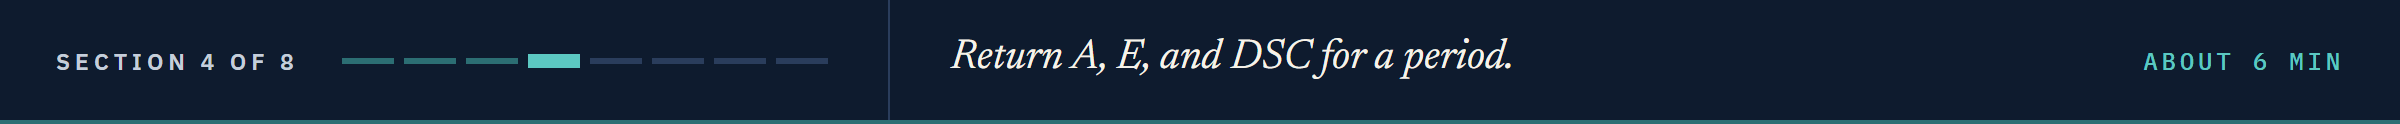

## 7.4 A, E, and DSC: `coupon_period_days`

The period drawn in 7.1 has three counts, in Excel's letters:

* **A**, the days accrued: `COUPDAYBS`.
* **E**, the days in the period: `COUPDAYS`, 360 / frequency on 30/360, so 180 for Quorvane.
* **DSC**, the days from settlement to the next coupon: E - A on 30/360, the count Excel's `PRICE` uses.

**Actual/actual** (Excel's basis 1, `'ACT/ACT'` in `bondmath`) counts all three in calendar days.

### Append It

`coupon_period_days(settlement, maturity, frequency=2, basis='30/360')` returns the three as a tuple, (A, E, DSC).
Any other basis stops with a `ValueError`; `!r` in its message shows the name as `repr()` does (Course 1's Analyzing Text, Part 1).

Q. Append `coupon_period_days` to `bondmath.py`.

In [15]:
%%writefile -a bondmath.py


def coupon_period_days(settlement: date, maturity: date, frequency: int = 2,
                       basis: str = "30/360") -> tuple[int, int, int]:
    """Day counts of the coupon period that holds settlement: (A, E, DSC).

    Units: whole days.
    A is days from the previous coupon to settlement (Excel COUPDAYBS).
    E is days in the coupon period: 360 / frequency under 30/360 (Excel COUPDAYS), and the actual days
    from the previous to the next coupon under ACT/ACT.
    DSC is days from settlement to the next coupon, as Excel's PRICE uses it: E - A under 30/360
    (this can differ from COUPDAYSNC near the end of February), actual days under ACT/ACT.
    """
    # stop on a basis the course does not use (coupon_dates checks frequency and dates)
    if basis not in ("30/360", "ACT/ACT"):
        raise ValueError(f'basis must be "30/360" or "ACT/ACT", not {basis!r}')
    # the previous and next coupon dates
    dates = coupon_dates(settlement, maturity, frequency)
    previous_coupon, next_coupon = dates[0], dates[1]
    if basis == "30/360":
        # 30/360: A by the 30/360 rules, a fixed period length, and DSC as what is left of it
        days_accrued = days_30_360(previous_coupon, settlement)
        days_in_period = 360 // frequency
        days_to_next = days_in_period - days_accrued
    else:
        # ACT/ACT: every count is actual calendar days
        days_accrued = (settlement - previous_coupon).days
        days_in_period = (next_coupon - previous_coupon).days
        days_to_next = (next_coupon - settlement).days
    return days_accrued, days_in_period, days_to_next

Appending to bondmath.py


### Quorvane on Both Bases

Q. What are Quorvane's A, E, and DSC on each basis, and what does Excel say?

In [16]:
importlib.reload(bondmath)
for basis in ['30/360', 'ACT/ACT']:
    print(basis, bondmath.coupon_period_days(settlement, quorvane_maturity, 2, basis))
quorvane = week2.loc['99001BZA7']
print('Excel, basis 0:', quorvane['coupdaybs'], quorvane['coupdays'], quorvane['coupdaysnc'])

30/360 (60, 180, 120)
ACT/ACT (61, 182, 121)
Excel, basis 0: 60 180 120


A + DSC = E on both bases, and Excel's three functions give the 30/360 line.

### E on Actual/Actual

Q. On basis 1, is Excel's `COUPDAYS` the period's calendar length?

In [17]:
basis1 = reference[reference['basis'] == 1]
# date minus date in days, as in Course 1's Combining and Loading Part 2
period_days = (pd.to_datetime(basis1['coupncd']) - pd.to_datetime(basis1['couppcd'])).dt.days
print(len(basis1), 'basis 1 rows;', (basis1['coupdays'] != period_days).sum(),
      'where COUPDAYS differs')

28 basis 1 rows; 12 where COUPDAYS differs


Not always, so on actual/actual E is `COUPNCD - COUPPCD`, the length `PRICE` uses.

### Where COUPDAYSNC Is Not E - A

Q. On basis 0, where does Excel's `COUPDAYSNC` differ from E - A?

In [18]:
basis0 = reference[reference['basis'] == 0]
nc_differs = basis0['coupdaysnc'] != basis0['coupdays'] - basis0['coupdaybs']
print(len(basis0), 'basis 0 rows;', nc_differs.sum(), 'where COUPDAYSNC is not E - A')
basis0.loc[nc_differs, ['settlement', 'couppcd', 'coupncd', 'coupdaybs', 'coupdays', 'coupdaysnc']]

278 basis 0 rows; 7 where COUPDAYSNC is not E - A


,settlement,couppcd,coupncd,coupdaybs,coupdays,coupdaysnc
case_id,,,,,,
99031FAF8,2026-09-30,2026-08-28,2027-02-28,32,180,150
edge_settle_feb_27_nonleap,2027-02-27,2026-08-28,2027-02-28,179,180,3
edge_settle_oct_30_mat_feb_28_leap,2026-10-30,2026-08-28,2027-02-28,62,180,120
edge_mat_feb_28_leap_not_month_end,2026-09-30,2026-08-28,2027-02-28,32,180,150
edge_mat_29_aug,2026-09-30,2026-08-29,2027-02-28,31,180,150
edge_mat_29_aug_leap_feb_coupon,2027-10-15,2027-08-29,2028-02-29,46,180,135
freq4_settle_feb_28_mat_29_nov,2027-02-28,2027-02-28,2027-05-29,0,90,89


Every one has a last day of February as settlement, previous coupon, or next coupon.
`99031FAF8` matures on 28 February 2036, not a month end in a leap year, so its next coupon is 28 February 2027.
E - A is 148 days, `COUPDAYSNC` 150, and the calendar 151; `PRICE` uses E - A, so `bondmath` does too.

### The Test

On 30/360 it checks A, E, and DSC against `COUPDAYBS`, `COUPDAYS`, and `COUPDAYS - COUPDAYBS`; on actual/actual, E against `COUPNCD - COUPPCD` and DSC against `COUPDAYSNC`.

Q. Append the test and run every test.

In [19]:
%%writefile -a test_bondmath.py


def test_coupon_period_days_match_excel():
    for row in REFERENCE:
        settlement, maturity, _, _, frequency, basis = bond_inputs(row)
        days_accrued, days_in_period, days_to_next = bondmath.coupon_period_days(settlement, maturity, frequency, basis)
        # A is COUPDAYBS under both bases
        assert days_accrued == int(row["coupdaybs"]), row["case_id"]
        if basis == "30/360":
            # E is COUPDAYS, and PRICE uses DSC = E - A
            assert days_in_period == int(row["coupdays"]), row["case_id"]
            assert days_to_next == int(row["coupdays"]) - int(row["coupdaybs"]), row["case_id"]
        else:
            # E is the actual length of the period, which PRICE uses (Excel's COUPDAYS with basis 1 can differ)
            period_start, period_end = date.fromisoformat(row["couppcd"]), date.fromisoformat(row["coupncd"])
            assert days_in_period == (period_end - period_start).days, row["case_id"]
            assert days_to_next == int(row["coupdaysnc"]), row["case_id"]

Appending to test_bondmath.py


In [20]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.................                                                        [100%]
17 passed in 0.50s



**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">A</td><td align="left"><code>bondmath.coupon_period_days(settlement, quorvane_maturity)[0]</code></td><td align="left"><code>=COUPDAYBS(DATE(2026,11,30),DATE(2031,9,30),2,0)</code></td><td align="left">60</td></tr>
<tr><td align="left">E</td><td align="left">the same, <code>[1]</code></td><td align="left"><code>=COUPDAYS(DATE(2026,11,30),DATE(2031,9,30),2,0)</code></td><td align="left">180</td></tr>
<tr><td align="left">DSC</td><td align="left">the same, <code>[2]</code></td><td align="left"><code>=COUPDAYSNC(DATE(2026,11,30),DATE(2031,9,30),2,0)</code>; <code>COUPDAYBS(...)+COUPDAYSNC(...)</code></td><td align="left">120; 180</td></tr>
<tr><td align="left">A on actual/actual</td><td align="left"><code>...(date(2026, 9, 30), date(2031, 4, 30), 2, 'ACT/ACT')[0]</code></td><td align="left"><code>=COUPDAYBS(DATE(2026,9,30),DATE(2031,4,30),2,1)</code></td><td align="left">153 (30/360: 150)</td></tr>
<tr><td align="left">E on actual/actual</td><td align="left"><code>...(date(2026, 9, 30), date(2031, 9, 30), 2, 'ACT/ACT')[1]</code></td><td align="left"><code>=COUPNCD(...)-COUPPCD(...)</code>; <code>=COUPDAYS(DATE(2026,9,30),DATE(2031,9,30),2,1)</code></td><td align="left">182; <code>COUPDAYS</code> 181</td></tr>
<tr><td align="left"><code>99031FAF8</code>'s DSC</td><td align="left"><code>...(date(2026, 9, 30), date(2036, 2, 28))[2]</code></td><td align="left"><code>=COUPDAYS(...)-COUPDAYBS(...)</code>; <code>=COUPDAYSNC(DATE(2026,9,30),DATE(2036,2,28),2,0)</code></td><td align="left">148; <code>COUPDAYSNC</code> 150</td></tr>
</table>
<br clear="left">

**A, E, and DSC are `COUPDAYBS`, `COUPDAYS`, and the E - A that `PRICE` uses, on every reference row.**

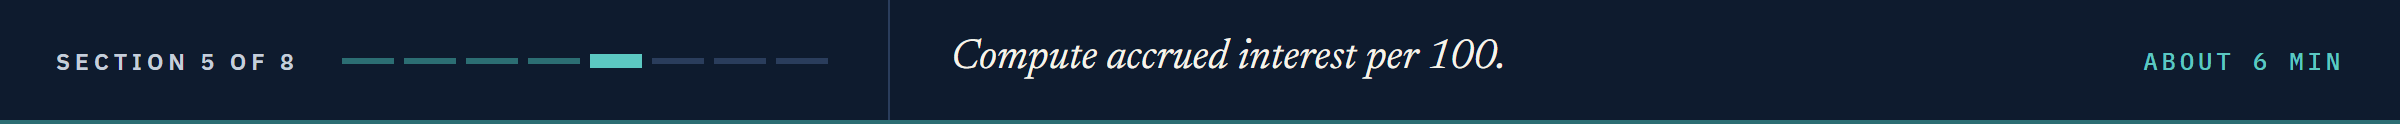

## 7.5 `accrued_interest`

### Append It

`accrued_interest` is 7.1's formula, with A and E from `coupon_period_days`.
Unpacking the tuple, `_` sets aside DSC, which accrued does not need.

Q. Append `accrued_interest` to `bondmath.py`.

In [21]:
%%writefile -a bondmath.py


def accrued_interest(settlement: date, maturity: date, coupon_pct: float, frequency: int = 2,
                     basis: str = "30/360") -> float:
    """Accrued interest the buyer pays the seller, per 100 of face.

    Units: coupon_pct in percent a year; the result is per 100 of face.
    Convention: coupon_pct / frequency x A / E, with A and E from coupon_period_days.
    Excel (30/360): =100*coupon_pct/100/frequency*COUPDAYBS(...)/COUPDAYS(...)
    """
    # A and E for this settlement
    days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
    # one coupon, times the share of the period that has passed
    return coupon_pct / frequency * days_accrued / days_in_period

Appending to bondmath.py


### Four Bonds Against Excel

Q. Does each bond's accrued on 30 November equal Excel's?

In [22]:
importlib.reload(bondmath)
accrued_table = pd.DataFrame({
    'ticker': bonds['ticker'],
    'python': [bondmath.accrued_interest(settlement, m, c)
               for m, c in zip(bonds['maturity'], bonds['coupon_pct'])],
    'excel': week2.loc[bonds['cusip'], 'accrued'].to_numpy(),
})
assert (accrued_table['python'] - accrued_table['excel']).abs().max() < 1e-9
accrued_table

,ticker,python,excel
0,QVNE,0.875000,0.875000
1,DNMR,1.020833,1.020833
2,PLWK,0.791667,0.791667
3,HLVF,1.250000,1.250000


The `assert` stayed silent: each is a third of its half-year coupon, 60 of 180 days.

**On 1,000,000 of Quorvane the buyer pays the seller 8,750.00 dollars, as Excel says.**

### Accrued Through One Period

Q. Settled on each day of Quorvane's period, how far apart are the two bases?

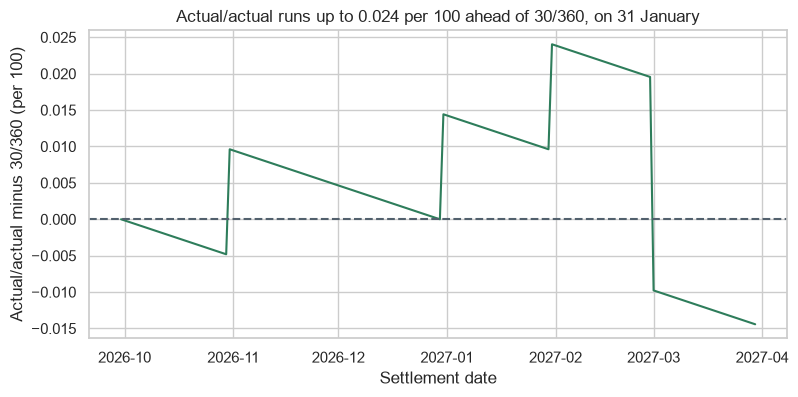

In [23]:
# every settlement day from the previous coupon to the day before the next: 182 days
settle_dates = [previous_coupon + timedelta(days=n) for n in range(182)]
gaps = [bondmath.accrued_interest(d, quorvane_maturity, 5.25, 2, 'ACT/ACT')
        - bondmath.accrued_interest(d, quorvane_maturity, 5.25) for d in settle_dates]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(settle_dates, gaps)
ax.axhline(0, color='#52606D', linestyle='--')
ax.set_title('Actual/actual runs up to 0.024 per 100 ahead of 30/360, on 31 January')
ax.set_xlabel('Settlement date')
ax.set_ylabel('Actual/actual minus 30/360 (per 100)')
plt.show()

On 30 November the gap is 0.004808 per 100, 48.08 dollars on 1,000,000 that one side overpays if the trade is booked on the wrong basis.
Each 31st is a day 30/360 does not count, so the gap jumps up there.
On 1 March 30/360 counts 3 days for one night, and stays ahead to the coupon.

### ACCRINT, the Second Route

Excel's `ACCRINT(issue, first_interest, settlement, rate, par, frequency, basis)` also returns accrued interest.
Given the previous and next coupon as its first two arguments, it gives Quorvane 0.875.

Q. Does it agree with the formula on all 306 rows?

In [24]:
blank = reference['accrint'].isna()
# a blank minus a number is NaN, and NaN > 1e-9 is False, so blanks are not counted as differences
differs = (reference['accrint'] - reference['accrued']).abs() > 1e-9
print('ACCRINT blank (#NUM! in Excel):', blank.sum(), ' different:', differs.sum())
print('99031FAF8, formula and ACCRINT:',
      reference.loc['99031FAF8', ['accrued', 'accrint']].tolist())

ACCRINT blank (#NUM! in Excel): 21  different: 9
99031FAF8, formula and ACCRINT: [0.7222222222222222, 0.7447916666666666]


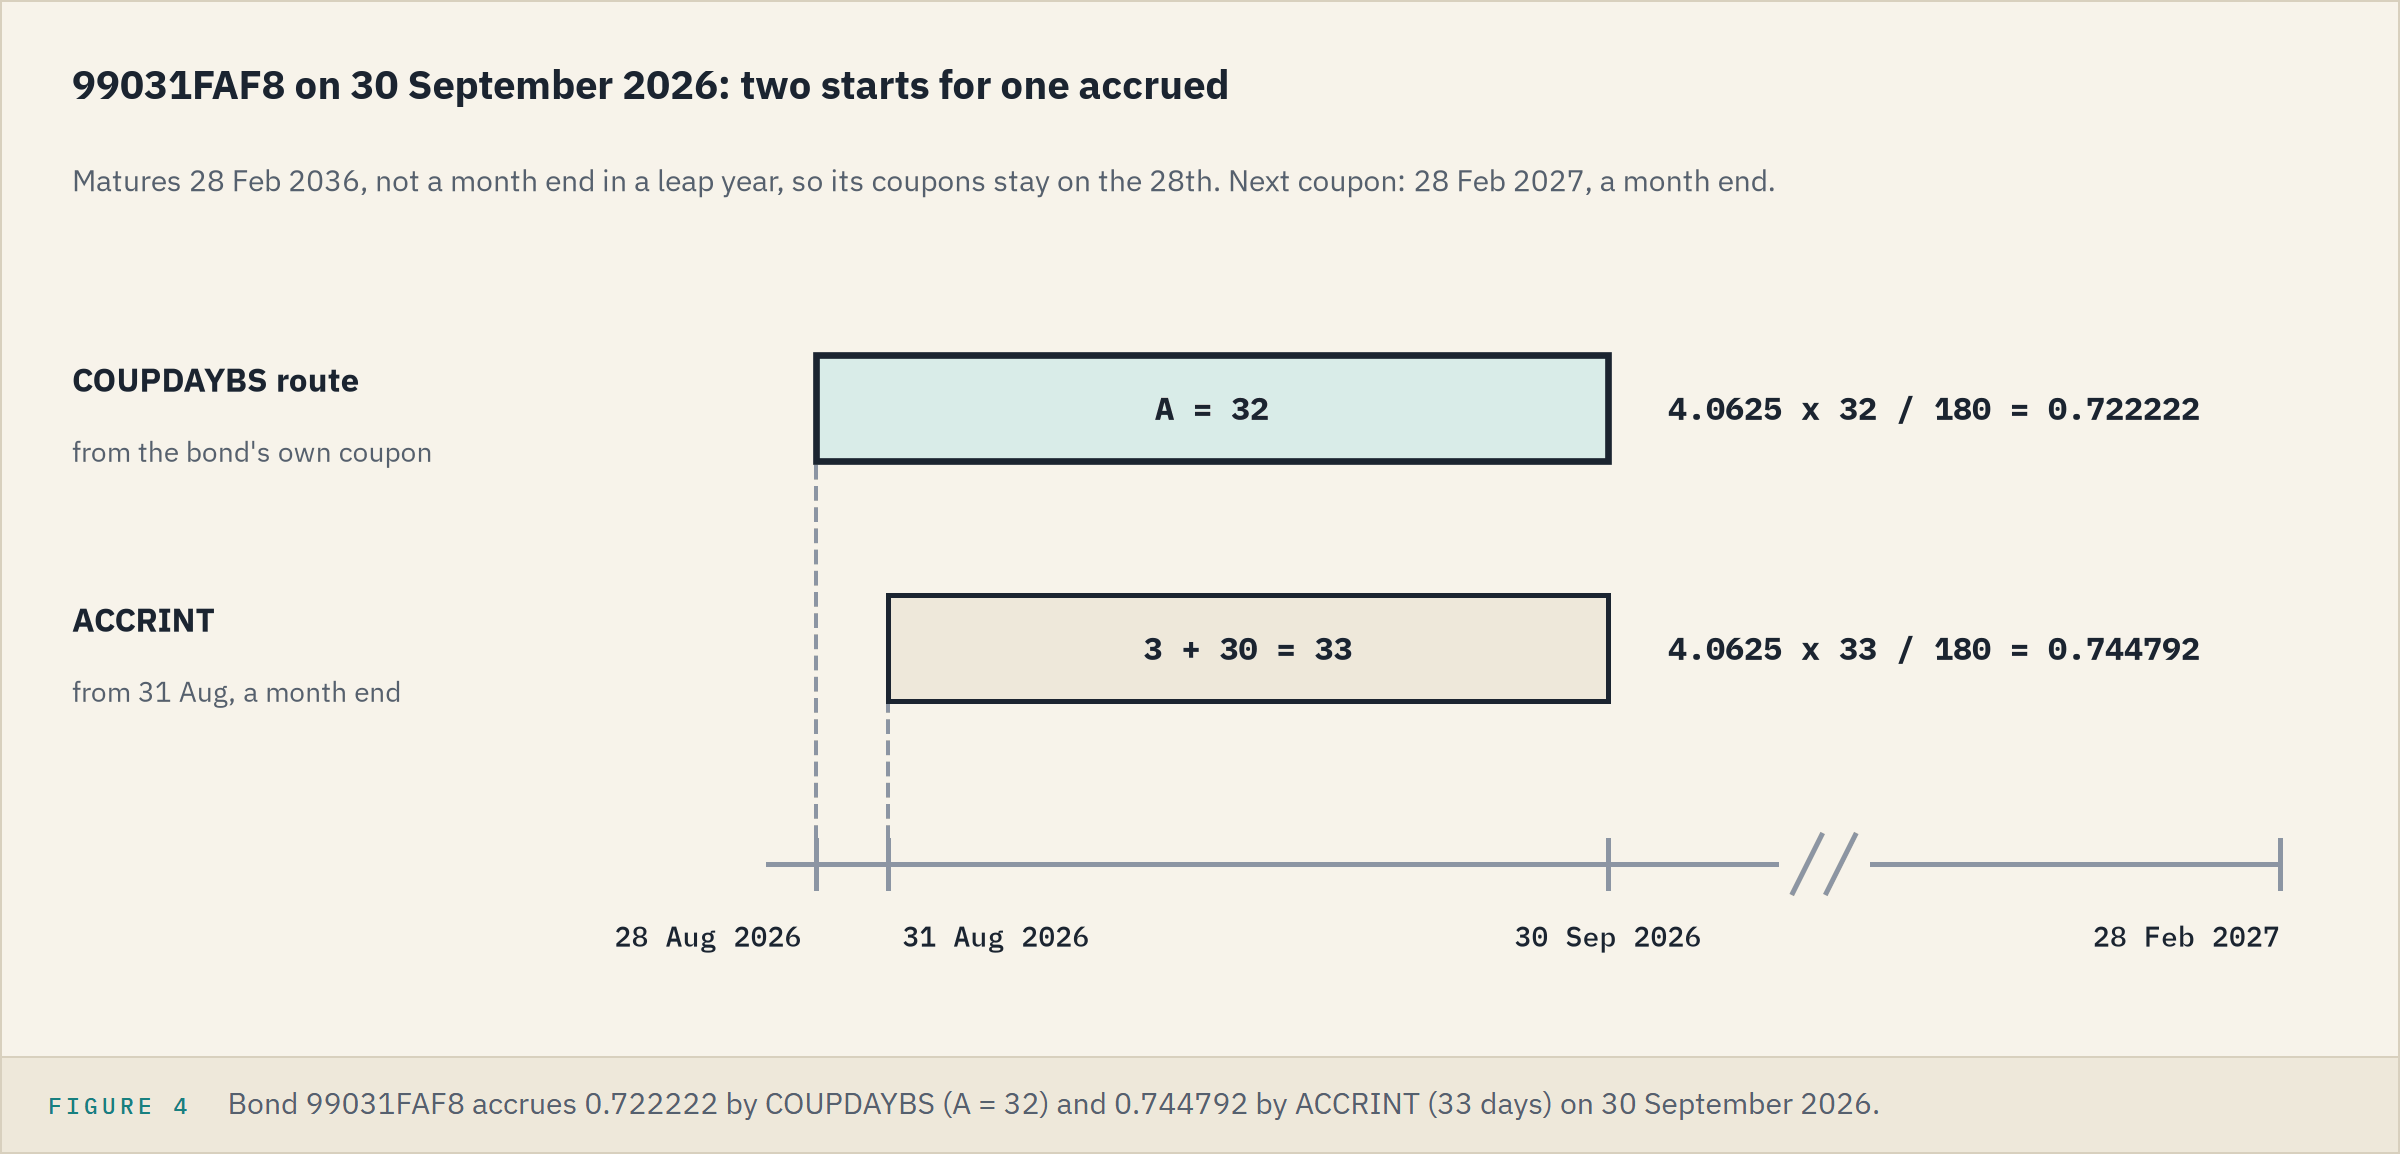

`ACCRINT` returns `#NUM!` when settlement is a coupon date or the coupon is 0, where the formula gives 0.
It counts its own period back from `first_interest`, the next coupon, and when that is a month end and maturity is not, it starts on another day.
The course follows the `COUPDAYBS` formula, the accrued that `PRICE` takes off in notebook 08.

### The Test

In [25]:
%%writefile -a test_bondmath.py


def test_accrued_matches_excel():
    for row in REFERENCE:
        settlement, maturity, coupon_pct, _, frequency, basis = bond_inputs(row)
        result = bondmath.accrued_interest(settlement, maturity, coupon_pct, frequency, basis)
        assert result == pytest.approx(float(row["accrued"]), abs=1e-9), row["case_id"]

Appending to test_bondmath.py


In [26]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..................                                                       [100%]
18 passed in 0.50s



**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Accrued, actual/actual</td><td align="left"><code>bondmath.accrued_interest(settlement, quorvane_maturity, 5.25, 2, 'ACT/ACT')</code></td><td align="left"><code>=100*5.25/100/2*COUPDAYBS(DATE(2026,11,30),DATE(2031,9,30),2,1)/(COUPNCD(DATE(2026,11,30),DATE(2031,9,30),2,1)-COUPPCD(DATE(2026,11,30),DATE(2031,9,30),2,1))</code></td><td align="left">0.879808</td></tr>
<tr><td align="left">The second route</td><td align="left"><code>bondmath.accrued_interest(settlement, quorvane_maturity, 5.25)</code></td><td align="left"><code>=ACCRINT(COUPPCD(DATE(2026,11,30),DATE(2031,9,30),2,0),COUPNCD(DATE(2026,11,30),DATE(2031,9,30),2,0),DATE(2026,11,30),5.25/100,100,2,0)</code></td><td align="left">0.875</td></tr>
<tr><td align="left">Where the routes part</td><td align="left"><code>bondmath.accrued_interest(date(2026, 9, 30), date(2036, 2, 28), 8.125)</code></td><td align="left">the formula, then <code>ACCRINT</code>, on <code>99031FAF8</code></td><td align="left">0.722222; <code>ACCRINT</code> 0.744792</td></tr>
</table>
<br clear="left">

**`accrued_interest` is Excel's accrued formula on all 306 rows, both bases: the desk pays the seller 8,750.00 dollars.**

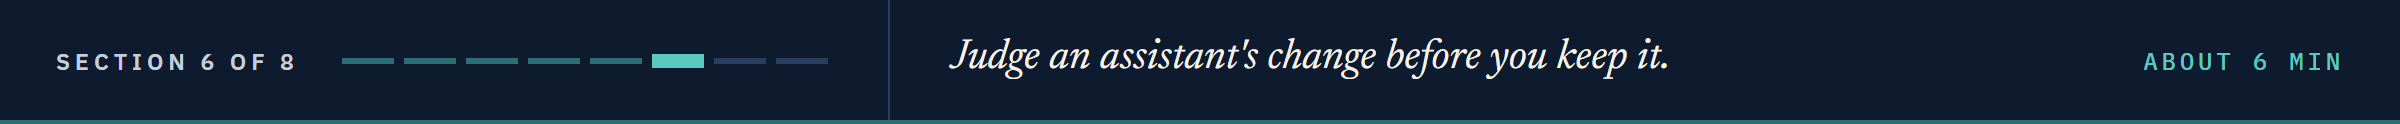

## 7.6 Read a Suggested Change Word by Word

### Commit the Day

Q. How much did today add? Then commit it.

In [27]:
!git -C "{work}" diff --stat
subject = 'Notebook 07: days_30_360, coupon_period_days, and accrued_interest'
body = 'The first money number of week 2; the counts follow COUPDAYBS and PRICE.'
!git -C "{work}" add bondmath.py test_bondmath.py
!git -C "{work}" commit -q -m "{subject}" -m "{body}"

 bondmath.py      | 75 ++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 test_bondmath.py | 56 ++++++++++++++++++++++++++++++++++++++++++
 2 files changed, 131 insertions(+)


### The Assistant's Tidy-Up

You paste `coupon_period_days` into an AI assistant and ask it to tidy the code.
It sends back one changed line, with a comment above it: *a year has 365 days*.

Q. Make its change to `bondmath.py`.

In [28]:
# the assistant's change, made here for the lesson
with open('bondmath.py', encoding='utf-8') as file:
    text = file.read()
new_lines = '# a year has 365 days\n        days_in_period = 365 // frequency'
with open('bondmath.py', 'w', encoding='utf-8') as file:
    file.write(text.replace('days_in_period = 360 // frequency', new_lines))

### Predict 3: The New Accrued

**Predict 3**

Quorvane's A stays 60, and the new line makes E `365 // 2`.

Q. What is Quorvane's accrued per 100 now? Write down a number.

In [29]:
importlib.reload(bondmath)
changed = bondmath.accrued_interest(settlement, quorvane_maturity, 5.25)
print(f'Accrued with the change: {changed:.6f}')

Accrued with the change: 0.865385


`//` drops the half, so E is 182: 2.625 x 60 / 182 = 0.865385.
No error, a plausible number, and wrong.

### Word by Word

Q. What exactly did the assistant change?

In [30]:
# --word-diff marks only the words that changed: [-removed-] and {+added+}
!git -C "{work}" diff --word-diff bondmath.py

diff --git a/bondmath.py b/bondmath.py
index 5a18c93..f5d6b06 100644
--- a/bondmath.py
+++ b/bondmath.py
@@ -251,7 +251,8 @@ def coupon_period_days(settlement: date, maturity: date, frequency: int = 2,
    if basis == "30/360":
        # 30/360: A by the 30/360 rules, a fixed period length, and DSC as what is left of it
        days_accrued = days_30_360(previous_coupon, settlement)
        {+# a year has 365 days+}
        days_in_period = [-360-]{+365+} // frequency
        days_to_next = days_in_period - days_accrued
    else:
        # ACT/ACT: every count is actual calendar days


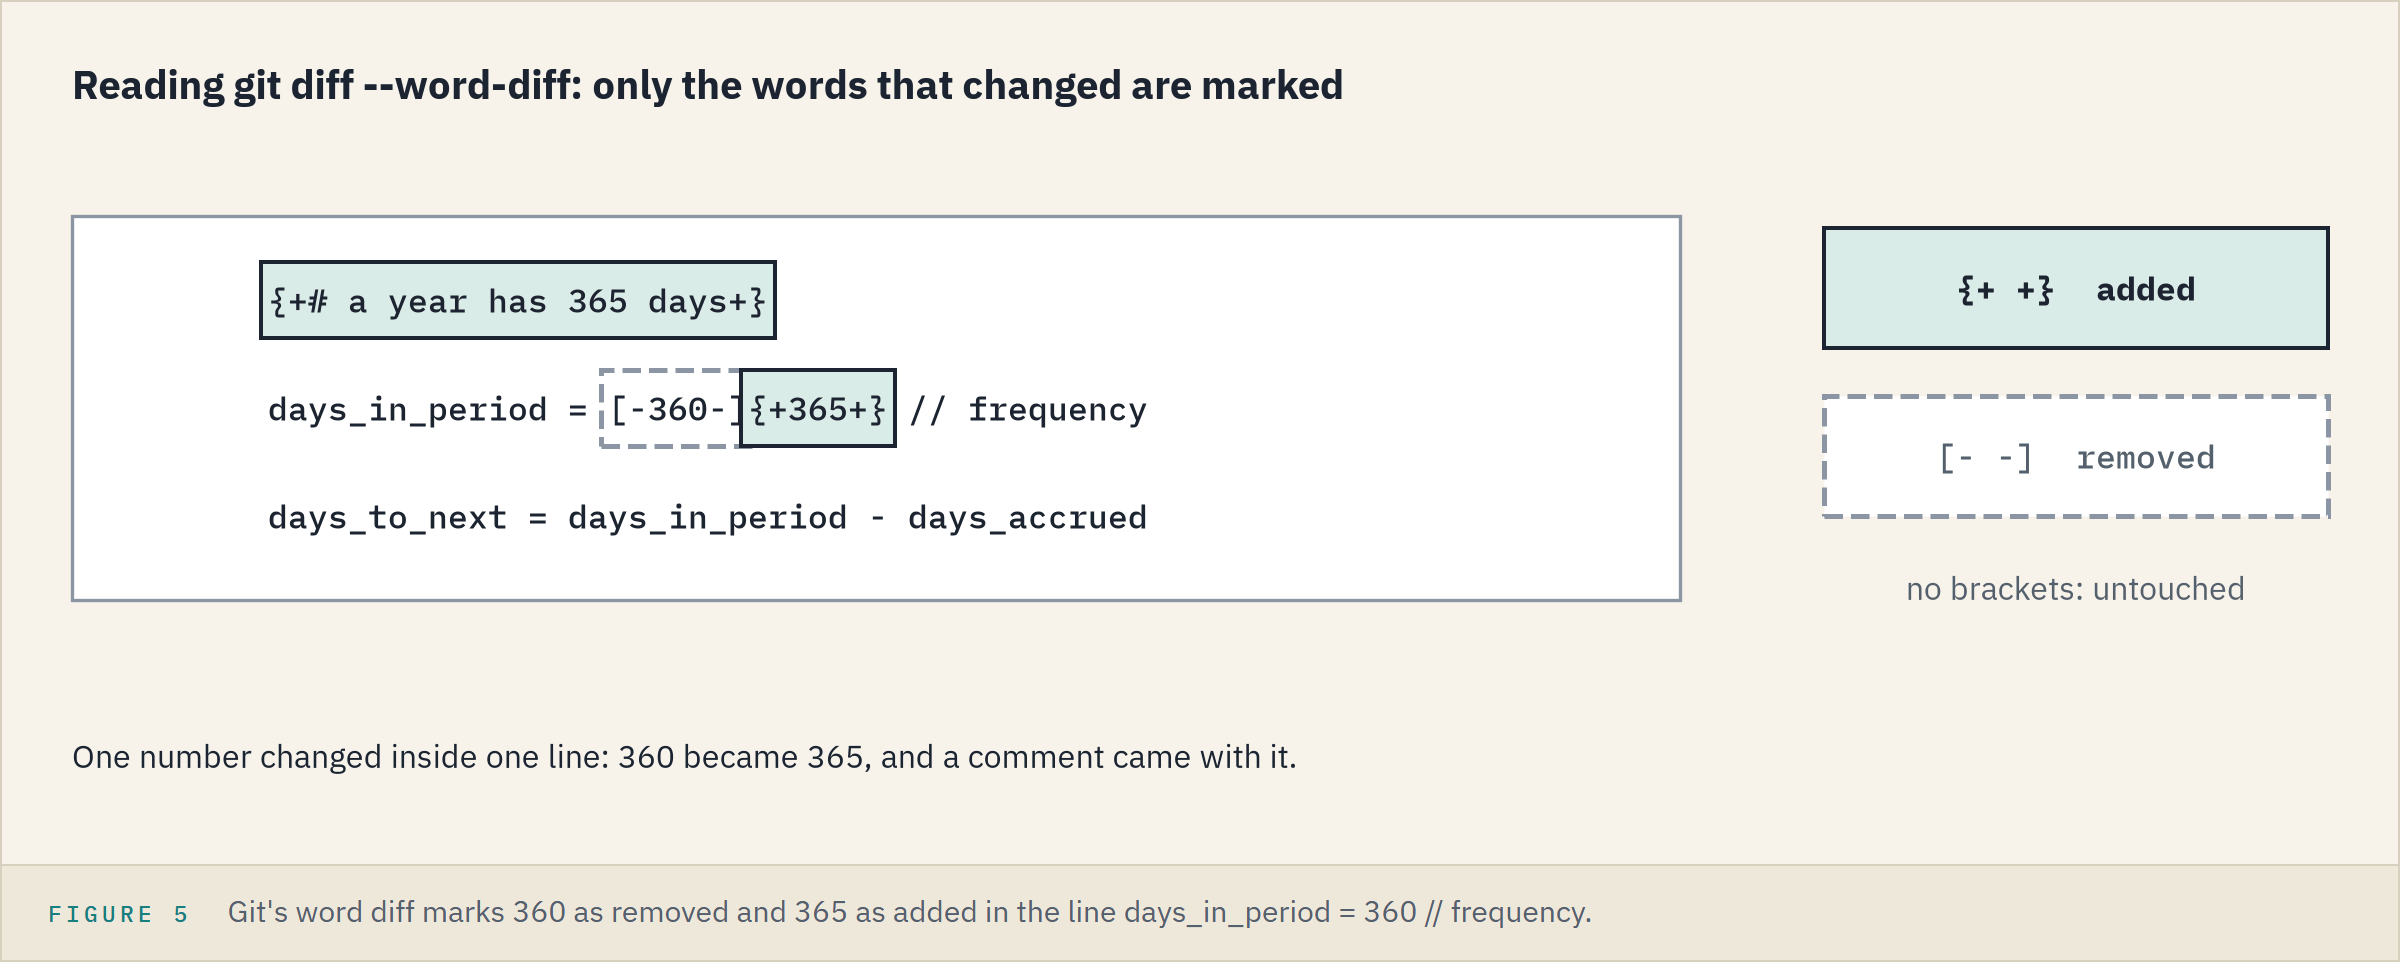

One number in one line, and a comment.
The comment is true of the calendar and beside the point: Quorvane is 30/360, and its period is 180 days.

### Predict 4: How Many Tests Fail?

**Predict 4**

Q. The change moves E from 180 to 182 and nothing else. Of the 18 tests:

A) none fail, the code still runs
B) one, the accrued test
C) two, the period test and the accrued test

### Run the Tests

`--tb=no` cuts pytest's output to its summary: one line for each failed test.

In [31]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', '--tb=no']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

................FF                                                       [100%]
=========================== short test summary info ===========================
FAILED test_bondmath.py::test_coupon_period_days_match_excel - AssertionError: 99080CAE8
FAILED test_bondmath.py::test_accrued_matches_excel - AssertionError: 99080CAE8
2 failed, 16 passed in 0.50s



C.
Both stop on the first reference row, `99080CAE8`, where E is now 182 and `COUPDAYS` says 180.
The tests from Excel catch the change the moment it is made.

### Throw It Away

`git restore` (notebook 04) puts the file back as it was committed.

In [32]:
!git -C "{work}" restore bondmath.py
importlib.reload(bondmath)
print(f'Accrued again: {bondmath.accrued_interest(settlement, quorvane_maturity, 5.25):.6f}')

Accrued again: 0.875000


In [33]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..................                                                       [100%]
18 passed in 0.50s



**Read every suggested change word by word and let the tests from Excel judge it: 360 is the convention, not a typo.**

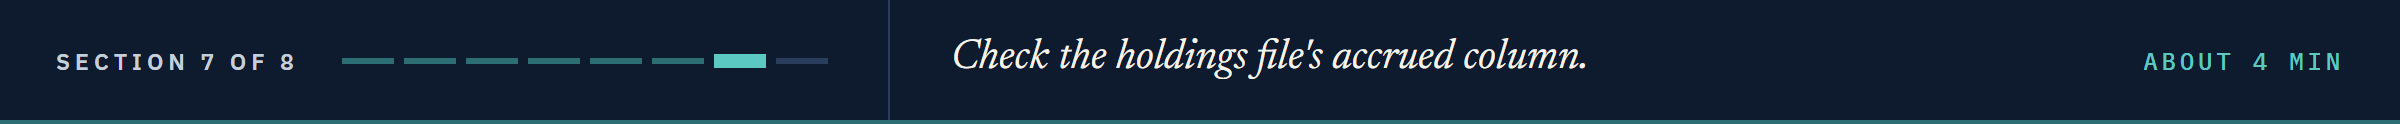

## 7.7 The Holdings File's `accrued` Column

`holdings.csv` gives each of its 200 bonds an `accrued` per 100 on 30 September 2026, rounded to 3 decimals.
Rounding to 3 decimals moves a number by at most 0.0005, half of the last decimal.

### Predict 5: The Largest Gap

**Predict 5**

Q. Across the 200 bonds, how close does the largest gap between `accrued_interest` and the file come to that limit?

A) on the limit, 0.0005000000
B) just inside, about 0.00049
C) well inside, about 0.0004

### Recompute All 200

In [34]:
holdings = pd.read_csv('holdings.csv')
holdings['accrued_python'] = [
    bondmath.accrued_interest(date.fromisoformat(a), date.fromisoformat(m), c)
    for a, m, c in zip(holdings['as_of_date'], holdings['maturity'], holdings['coupon'])]
holdings['gap'] = (holdings['accrued_python'] - holdings['accrued']).abs()
print(f"Largest gap: {holdings['gap'].max():.10f} per 100")

Largest gap: 0.0005000000 per 100


### The Bond at the Limit

In [35]:
# idxmax gives the row label of the largest gap, as in Course 1's Visualization notebook
worst = holdings.loc[holdings['gap'].idxmax()]
print(worst['cusip'], ' file', worst['accrued'], ' ours', worst['accrued_python'],
      ' gap', worst['gap'])

99113JAA2  file 0.087  ours 0.0875  gap 0.0005000000000000004


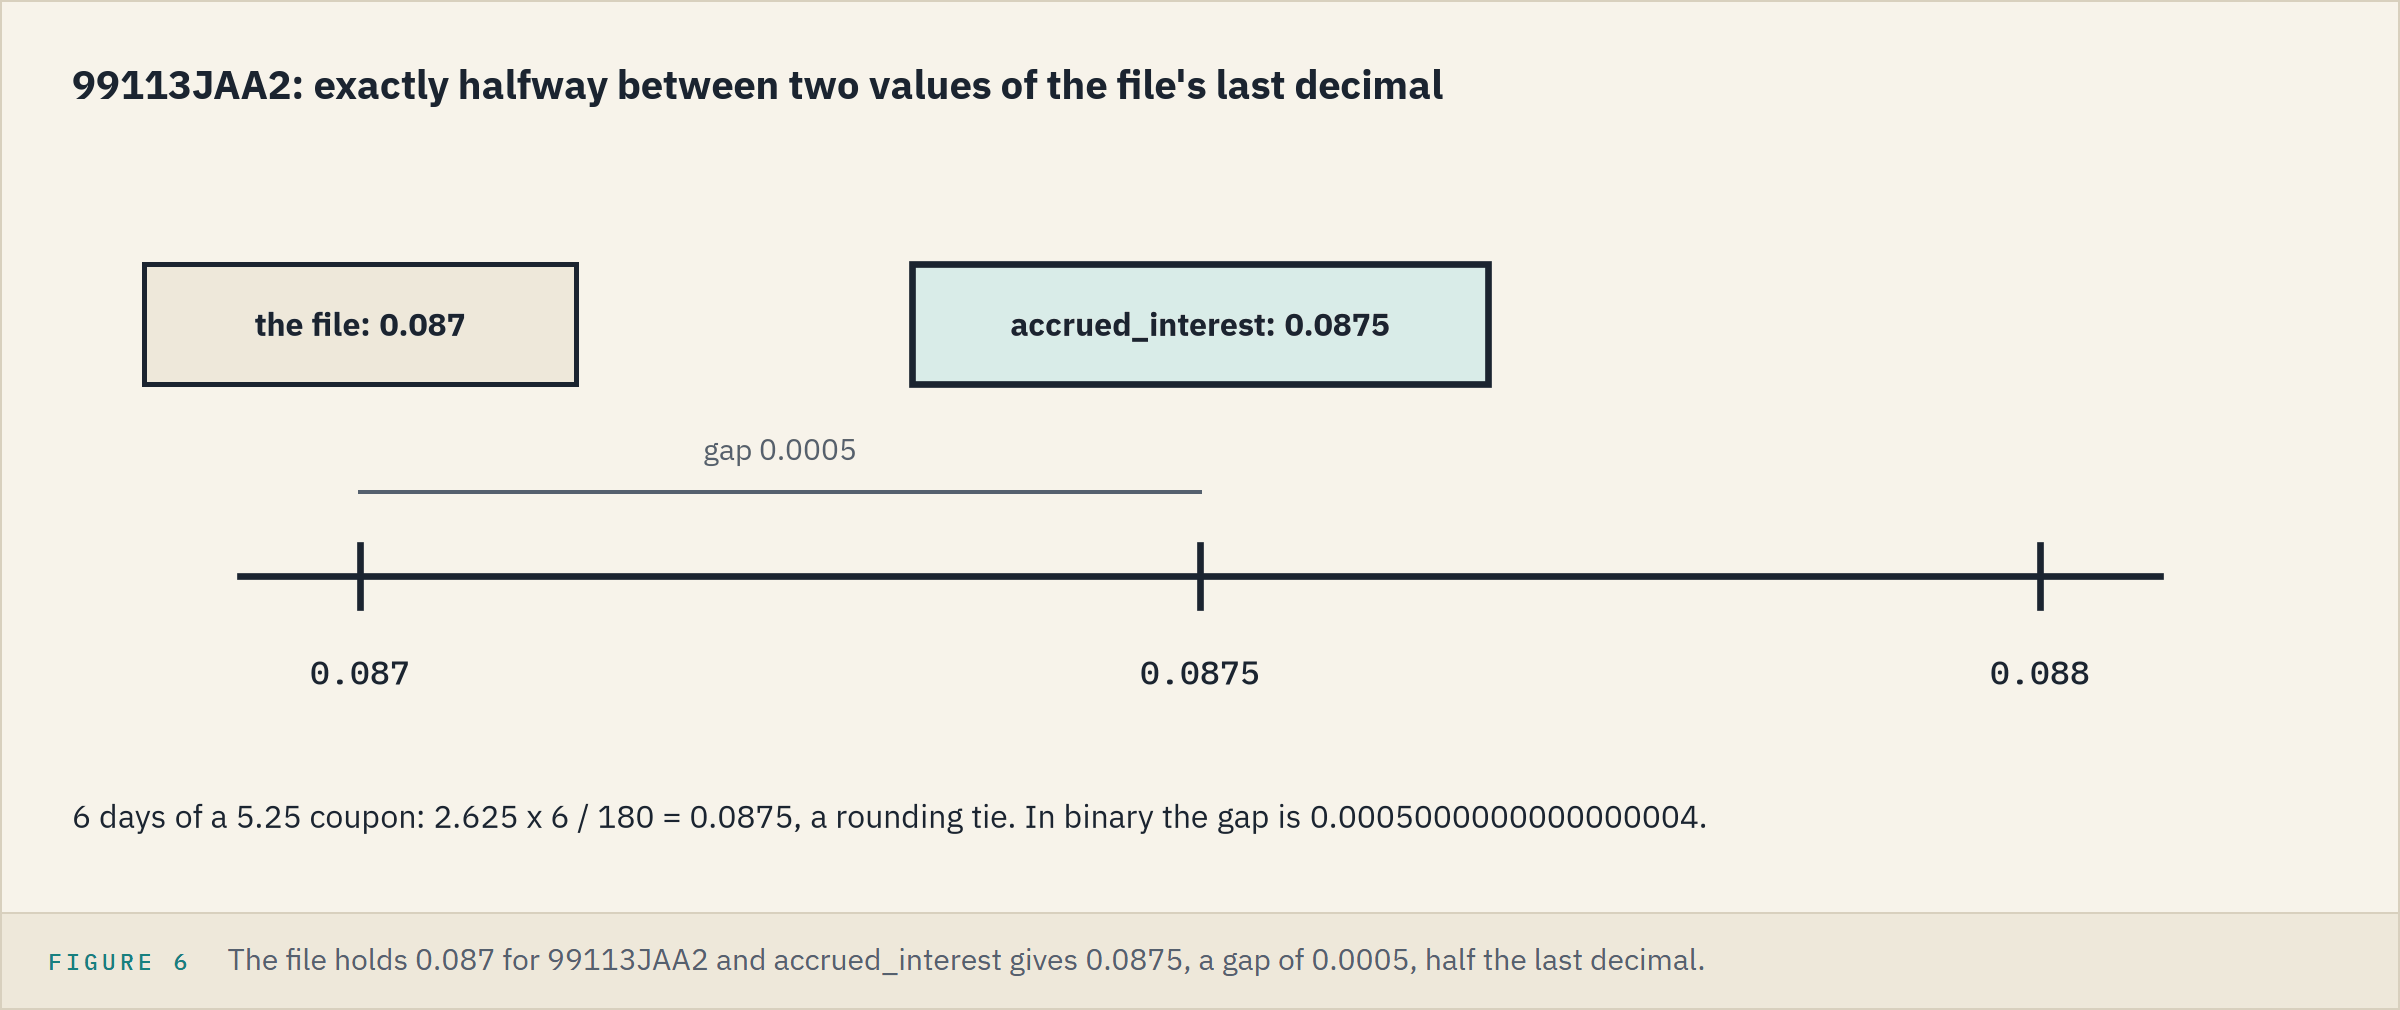

A.
`99113JAA2` sits exactly halfway between 0.087 and 0.088, a **rounding tie**, and the file rounded it down.
Binary arithmetic adds a hair to the gap, so the check allows 0.0005 plus 1e-9.

### Check, and Count the Ties

In [36]:
# the rounding limit, plus a hair for floating point
assert holdings['gap'].max() <= 0.0005 + 1e-9, 'a bond is off by more than rounding'
print('Bonds at a rounding tie:', ((holdings['gap'] - 0.0005).abs() < 1e-9).sum())

Bonds at a rounding tie: 7


### Every Gap

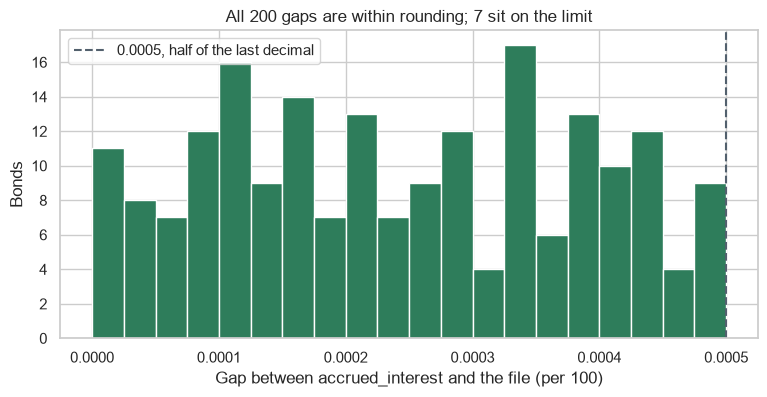

In [37]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(holdings['gap'], bins=20)
ax.axvline(0.0005, color='#52606D', linestyle='--', label='0.0005, half of the last decimal')
ax.set_title('All 200 gaps are within rounding; 7 sit on the limit')
ax.set_xlabel('Gap between accrued_interest and the file (per 100)')
ax.set_ylabel('Bonds')
ax.legend()
plt.show()

`99031FAF8` is in the file at 0.722: the `COUPDAYBS` route, not `ACCRINT`'s 0.7448.

**All 200 accrued values are ours to the file's last decimal; the largest gap is a rounding tie.**

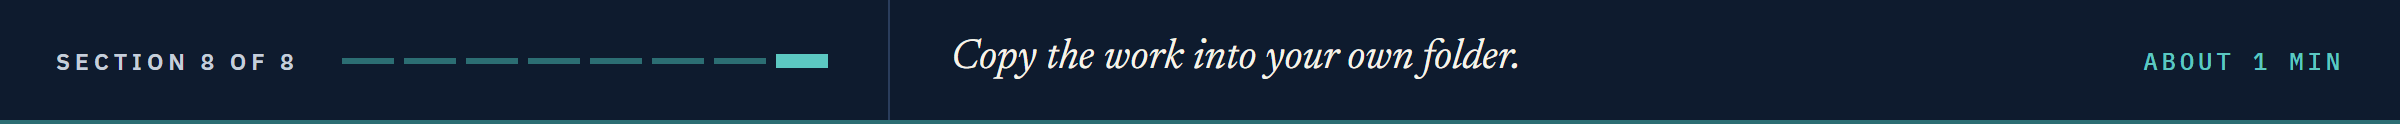

## Bring It Home

Copy the work folder's three files into your own `my_bondmath` folder, then test and commit there.
The copy replaces your files, so anything of your own goes into the work folder first.
In a PowerShell terminal in VS Code, with the course's `.venv` active, use the work folder name your setup cell printed:

```powershell
Set-Location "$HOME\projects\my_bondmath"
$work = "$env:TEMP\pfi_course2_07_k4w7q2xr"
Copy-Item "$work\bondmath.py", "$work\test_bondmath.py", "$work\.gitignore" .
python -m pytest -q
git diff --stat
git add bondmath.py test_bondmath.py .gitignore
git commit -m "Notebook 07: days_30_360, coupon_period_days, and accrued_interest"
```

Keep the habit: read any suggested edit with `git diff --word-diff`, run `python -m pytest -q`, and `git restore` it if a test fails.
In Colab, download the three files instead.
The work folder stays in your temp folder until you delete it.

## You Can Now

By the end of this notebook, you can:

* Compute accrued interest as one coupon times A / E, and say why the buyer pays it.
* Count days on US 30/360 with `days_30_360` or `YEARFRAC(..., 0)`, and say where `DAYS360` differs.
* Count a period on actual/actual, with E as `COUPNCD - COUPPCD`.
* Return A, E, and DSC with `coupon_period_days`, tied to Excel's `COUP` functions.
* Compute accrued with `accrued_interest`, and say when `ACCRINT` differs.
* Read a suggested change with `git diff --word-diff`, judge it with pytest, and discard it with `git restore`.
* Explain a gap of exactly half a file's last decimal.

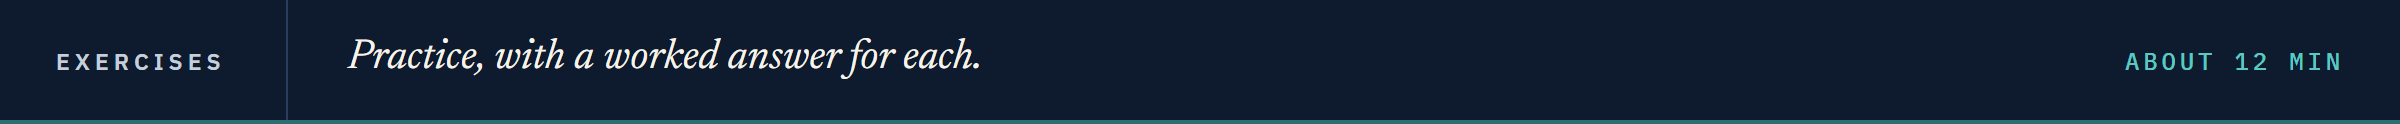

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The second set of week 1 bonds, one trade each, all accruing from 30 September 2026 on 30/360.
Replace each `...` with your code, then run the check cell under it.
Run the next two cells first.

In [38]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [39]:
exercise_bonds = pd.DataFrame({
    'ticker': ['OSTV', 'TRNW', 'OSMC', 'CLDB'],
    'issuer': ['Ostrevale Telecom', 'Tarnwick Utilities', 'Osmere Chemicals', 'Calderby Retail'],
    'coupon_pct': [5.625, 4.375, 5.0, 8.25],
    'maturity': [date(2030, 9, 30), date(2028, 9, 30), date(2032, 9, 30), date(2034, 9, 30)],
})
# one trade in each bond: the settlement date and the face, in dollars
exercise_trades = pd.DataFrame({
    'ticker': ['OSTV', 'TRNW', 'OSMC', 'CLDB'],
    'settlement': [date(2027, 2, 28), date(2027, 3, 1), date(2026, 12, 31), date(2027, 1, 15)],
    'par': [2_000_000, 5_000_000, 3_000_000, 1_500_000],
}).merge(exercise_bonds[['ticker', 'coupon_pct', 'maturity']], on='ticker')
exercise_trades

,ticker,settlement,par,coupon_pct,maturity
0,OSTV,2027-02-28,2000000,5.625,2030-09-30
1,TRNW,2027-03-01,5000000,4.375,2028-09-30
2,OSMC,2026-12-31,3000000,5.000,2032-09-30
3,CLDB,2027-01-15,1500000,8.250,2034-09-30


### Exercise 1

Q. For each trade, find A with `bondmath.coupon_period_days` and the accrued per 100 with `bondmath.accrued_interest`. Store Ostrevale's A in **ex1_days** and its accrued in **ex1_accrued**.

In [40]:
ex1_days = ...
ex1_accrued = ...

In [41]:
check('Exercise 1 Ostrevale days accrued', ex1_days, 148)
check('Exercise 1 Ostrevale accrued per 100', ex1_accrued, 2.3125)

Exercise 1 Ostrevale days accrued: not attempted yet
Exercise 1 Ostrevale accrued per 100: not attempted yet


### Exercise 2

Q. For each trade, count the calendar days from 30 September 2026 to settlement and take away its A. Store the ticker with the largest gap in **ex2_ticker** and the gap, in days, in **ex2_gap**.

In [42]:
ex2_ticker = ...
ex2_gap = ...

In [43]:
check('Exercise 2 ticker with the largest gap', ex2_ticker, 'OSTV')
check('Exercise 2 largest gap in days', ex2_gap, 3)

Exercise 2 ticker with the largest gap: not attempted yet
Exercise 2 largest gap in days: not attempted yet


### Exercise 3

Q. Add `accrued_dollars(par, accrued_per_100)`, the accrued on a position in dollars, docstring first. Test it in `test_accrued_dollars_hand_case`: 1,000,000 of Quorvane at 0.875 per 100, and nothing accrued. Run 7.6's last pytest cell, reload, and store the dollars over the four trades in **ex3_total**.

In [44]:
%%writefile -a bondmath.py


# Exercise 3: write accrued_dollars(par, accrued_per_100) below this line

Appending to bondmath.py


In [45]:
%%writefile -a test_bondmath.py


# Exercise 3: write test_accrued_dollars_hand_case() below this line

Appending to test_bondmath.py


In [46]:
# reload the module, then call your function on every trade
ex3_total = ...

In [47]:
check('Exercise 3 accrued in dollars, four trades', ex3_total, 211597.22222222222)

Exercise 3 accrued in dollars, four trades: not attempted yet


### Exercise 4: AI check

You gave an AI assistant `accrued_interest`'s docstring as the request: the docstring is the prompt.
This came back, written for this course in the style of an assistant's answer.

In [48]:
# written for this course in the style of an AI assistant's answer.
# It runs, and it contains one bug.
def assistant_accrued_interest(settlement, maturity, coupon_pct, frequency=2, basis='30/360'):
    """Accrued interest the buyer pays the seller, per 100 of face.

    Units: coupon_pct in percent a year; the result is per 100 of face.
    Convention: coupon_pct / frequency x A / E, with A and E from coupon_period_days.
    Excel (30/360): =100*coupon_pct/100/frequency*COUPDAYBS(...)/COUPDAYS(...)
    """
    if basis not in ('30/360', 'ACT/ACT'):
        raise ValueError(f'basis must be "30/360" or "ACT/ACT", not {basis!r}')
    previous_coupon = bondmath.coupon_dates(settlement, maturity, frequency)[0]
    # the days the seller has held the bond, as a share of a year
    days_held = (settlement - previous_coupon).days
    return coupon_pct * days_held / 365

Q. What should Quorvane's accrued be on 30 November 2026? Section 7.5 has it. Run the function.

In [49]:
print(f'Quorvane: {assistant_accrued_interest(settlement, quorvane_maturity, 5.25):.6f} per 100')

Quorvane: 0.877397 per 100


Q. Test it against every row of Excel's file before you trust it.

In [50]:
rows = pd.read_csv('bondmath_excel_reference.csv')
for case, s, m, c, f, b, excel in zip(rows['case_id'], rows['settlement'], rows['maturity'],
                                      rows['coupon_pct'], rows['frequency'], rows['basis'],
                                      rows['accrued']):
    basis = '30/360' if b == 0 else 'ACT/ACT'
    result = assistant_accrued_interest(date.fromisoformat(s), date.fromisoformat(m), c, f, basis)
    assert abs(result - excel) < 1e-9, f'{case}: accrued {result:.6f}, Excel {excel:.6f}'
print(f'All {len(rows)} rows match Excel')

AssertionError: 99080CAE8: accrued 1.994521, Excel 1.983333

Q. Fix the convention the code broke and run the test again. Store the fixed function's accrued for Quorvane on 30 November 2026 in **ex4_quorvane**, and for Osmere's trade in **ex4_osmere**.

In [51]:
ex4_quorvane = ...
ex4_osmere = ...

In [52]:
check('Exercise 4 Quorvane accrued', ex4_quorvane, 0.875)
check('Exercise 4 Osmere accrued', ex4_osmere, 1.25)

Exercise 4 Quorvane accrued: not attempted yet
Exercise 4 Osmere accrued: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Accrued per 100</td><td align="left">0.875, 60 of 180 days on 30/360</td></tr>
<tr><td align="left">In dollars</td><td align="left">8,750.00 on 1,000,000 of face</td></tr>
<tr><td align="left">Why the calendar differs</td><td align="left">61 of 182 days is actual/actual, 0.879808, another convention</td></tr>
<tr><td align="left">Day counts in <code>bondmath</code></td><td align="left"><code>days_30_360</code>, <code>coupon_period_days</code>, <code>accrued_interest</code>, 18 tests over 306 rows</td></tr>
<tr><td align="left">The assistant's change</td><td align="left">Rejected: 360 became 365, two tests failed, <code>git restore</code></td></tr>
<tr><td align="left">The holdings column</td><td align="left">200 of 200 within rounding, the largest gap a rounding tie</td></tr>
</table>
<br clear="left">

Be proud: you can say to the cent what a buyer owes a seller on any day, and why two systems may disagree.

Next, Clean and Dirty Price (notebook 08) prices this trade between coupons: the quote plus today's accrued.

[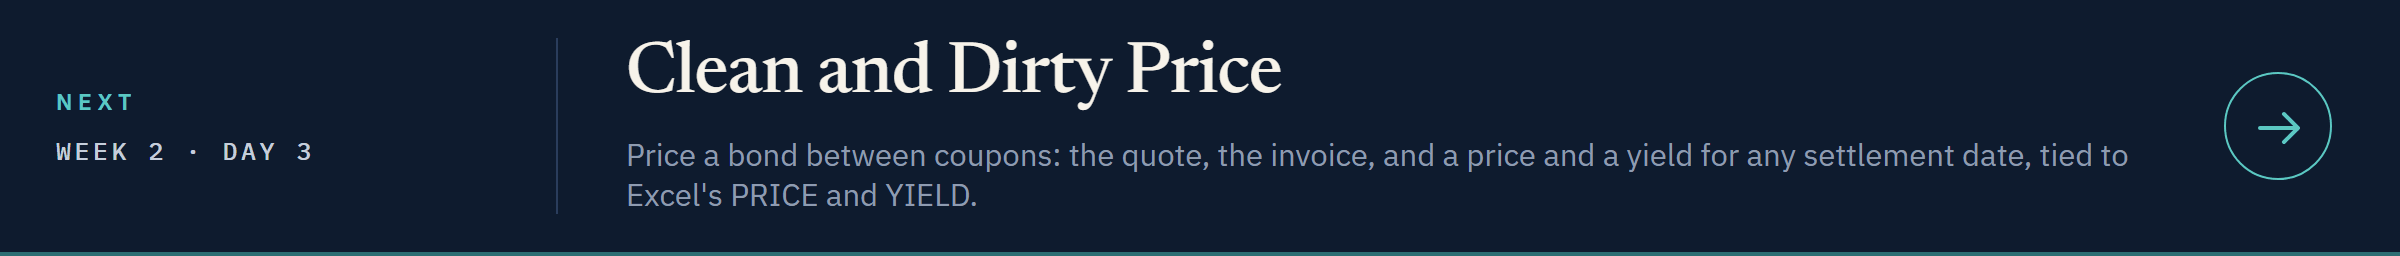](../day3/08_clean_and_dirty_price.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week2/day3/08_clean_and_dirty_price.ipynb)